# Capítulo 6 — Estatísticas, distribuições amostrais e intervalos de confiança

Neste capítulo vamos trabalhar com uma mudança de pergunta. Antes, estudamos a distribuição de uma medida $X$. Agora queremos entender a distribuição de uma quantidade **calculada a partir de várias medidas**, como a média $\bar X$ ou a variância $S^2$. Depois usaremos essas distribuições para construir intervalos para os parâmetros da população.

O notebook segue os **slides 55–84 da Parte II**, na versão atual de Estatística Bayesiana, e o **capítulo 6 do Gregory, pp. 139–161**. Está organizado em duas partes, mantendo o encadeamento: definir o experimento e suas hipóteses, estabelecer a notação, abrir a conta, visualizar e interpretar.

| Parte | Conteúdo | Pergunta que guia a leitura |
|:--|:--|:--|
| **1. Estatísticas e suas distribuições** | $\chi^2$, $\chi$, $\chi^2$ reduzido, $S^2$, $S$, Student e $F$; teoremas 1–5 | O que muda quando o conjunto de dados muda? |
| **2. Intervalos de confiança** | Média, diferença de médias, variância e razão de variâncias; interpretação e cobertura | Como usar a distribuição amostral sem transformá-la em uma posterior? |

Todas as definições necessárias serão retomadas aqui. Os dados simulados são gerados no próprio notebook; não há dependência de arquivos externos ou dos notebooks anteriores. Precisamos apenas de **NumPy, SciPy, Matplotlib e pandas**. Para instalar: `python -m pip install numpy scipy matplotlib pandas jupyterlab`. No Jupyter, reinicie o kernel e execute as células em ordem.

As saídas já estão incluídas. As sementes são fixas e as verificações numéricas aparecem ao longo da leitura. Para exportar as figuras em PDF e PNG, ative `SALVAR_FIGURAS` na próxima célula. A escrita usa a organização da versão atual da Lista 1 como referência, com as deduções desenvolvidas aqui para que o conteúdo também seja autocontido.

In [1]:
# Configuração comum: bibliotecas, cores e saídas das figuras.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special, integrate, optimize, linalg
from IPython.display import display

SEMENTE = 20261006
rng = np.random.default_rng(SEMENTE)
SALVAR_FIGURAS = False
PASTA_FIGURAS = Path('figuras_capitulo_6')
CORES = {'verde':'#24856a', 'roxo':'#7653aa', 'laranja':'#db8431',
         'azul':'#3477a2', 'vermelho':'#c35757', 'cinza':'#586271'}
plt.rcParams.update({'figure.figsize':(10,4.3), 'figure.dpi':115,
                     'font.size':11, 'axes.spines.top':False,
                     'axes.spines.right':False, 'axes.grid':True,
                     'grid.alpha':0.18, 'lines.linewidth':2.2,
                     'savefig.bbox':'tight'})
pd.set_option('display.precision', 5)
VERIFICACOES = []
FIGURAS = []

def verificar(nome, condicao):
    """Registrar uma comparação científica e interromper se ela falhar."""
    if not bool(np.all(condicao)):
        raise AssertionError(nome)
    VERIFICACOES.append(nome)

def figura(fig, nome):
    """Exibir a figura e, opcionalmente, exportá-la em PDF e PNG."""
    fig.tight_layout()
    FIGURAS.append(nome)
    if SALVAR_FIGURAS:
        PASTA_FIGURAS.mkdir(exist_ok=True)
        fig.savefig(PASTA_FIGURAS / f'{nome}.pdf')
        fig.savefig(PASTA_FIGURAS / f'{nome}.png', dpi=220)
    plt.show()
    plt.close(fig)

print('Cada linha de uma matriz de simulação representará um experimento completo.')

Cada linha de uma matriz de simulação representará um experimento completo.


## Parte 1 — Uma função dos dados também tem uma distribuição
### 1.1 O que significa “não conter quantidades desconhecidas”? — slides 56–57

Considere $X_1,\ldots,X_n$ medidas IID: independentes e com a mesma distribuição. Uma realização é $D=(x_1,\ldots,x_n)$. Uma **estatística** é uma função $A=a(X_1,\ldots,X_n)$ que pode ser calculada usando os dados e as informações conhecidas, sem precisar inserir parâmetros desconhecidos.

A frase dos slides não significa que “as variáveis precisam ser conhecidas antes de medir”. Antes da observação, $X_i$ e $A$ são variáveis aleatórias. Depois, $x_i$ e $a(D)$ são números. O que não pode aparecer na **regra de cálculo** é uma incógnita como a verdadeira média $\mu$ que estamos tentando estimar.

| Expressão | Pode ser calculada dos dados? | Classificação, se $\mu,\sigma$ são desconhecidos |
|:--|:--|:--|
| $\bar X=n^{-1}\sum_iX_i$ | Sim | Estatística; estimador da média |
| $S^2=(n-1)^{-1}\sum_i(X_i-\bar X)^2$ | Sim | Estatística; estimador da variância |
| $S/\sqrt n$ | Sim, para $n\geq2$ | Estatística; erro padrão estimado |
| $(\bar X-\mu)/(\sigma/\sqrt n)$ | Não | Quantidade pivotal, sob o modelo normal |

Um **estimador** é uma estatística usada para estimar um parâmetro. Uma **estimativa** é seu valor observado. Um **pivô** é uma função dos dados e dos parâmetros cuja distribuição não depende dos parâmetros desconhecidos. O pivô pode conter $\mu$ e $\sigma$: usamos sua distribuição para inverter desigualdades e obter um intervalo calculável. Sob uma hipótese especificada, $\mu=\mu_0$, a quantidade $(\bar X-\mu_0)/(S/\sqrt n)$ já é calculável.

A estatística pode ter uma distribuição que **depende** de parâmetros desconhecidos, mesmo sem contê-los na sua definição. Por exemplo, $\bar X$ não contém $\mu$, mas sua distribuição é centrada em $\mu$.

### 1.2 Uma amostra de dez medidas não é dez médias

Usaremos $i$ para a medida dentro da amostra e $r$ para a repetição do experimento:

$$X_{ri},\qquad i=1,\ldots,n,\quad r=1,\ldots,R,$$
$$\bar X_r=\frac1n\sum_{i=1}^nX_{ri}.$$

Em um experimento real com $n=10$, registramos dez valores e calculamos **uma** média $\bar x$. Para obter um histograma de médias, na simulação fazemos $R$ experimentos completos, cada um com dez novas medidas. Os $R$ valores $\bar x_r$ ilustram a **distribuição amostral da média**. Essa distribuição existe matematicamente; não precisamos repetir o experimento na prática para usar um teorema que a descreva.

Neste notebook $\mathcal N(\mu,\sigma^2)$ sempre usa **a variância como segundo argumento**. Nos slides, o segundo argumento de $N$ às vezes é o desvio padrão; por isso escreveremos as unidades e o significado explicitamente. Se $X_i\sim\mathcal N(\mu,\sigma^2)$, então, exatamente,

$$\bar X\sim\mathcal N\!\left(\mu,\frac{\sigma^2}{n}\right),\qquad
\operatorname{sd}(\bar X)=\frac{\sigma}{\sqrt n}.$$

A média de gaussianas independentes é gaussiana para qualquer $n$. Para uma população não gaussiana de variância finita, a média e a variância acima continuam corretas; a **forma gaussiana** é, em geral, uma aproximação do TLC.

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10
experimento 1,4.46646,3.76934,5.74689,5.55065,4.19542,5.93745,6.62694,5.39260,5.17809,5.27295
experimento 2,4.73684,5.88329,4.70531,3.94789,5.64405,5.81471,5.22753,4.74417,5.97168,6.67318
experimento 3,5.92330,4.02813,6.50633,6.54656,7.58108,4.57090,5.53846,6.89868,3.89916,3.17331
experimento 4,4.62220,6.99899,4.81282,5.44416,4.69094,5.54707,5.57815,4.69675,3.99271,4.97556


Uma amostra: média = 5.2137; S² = 0.7375


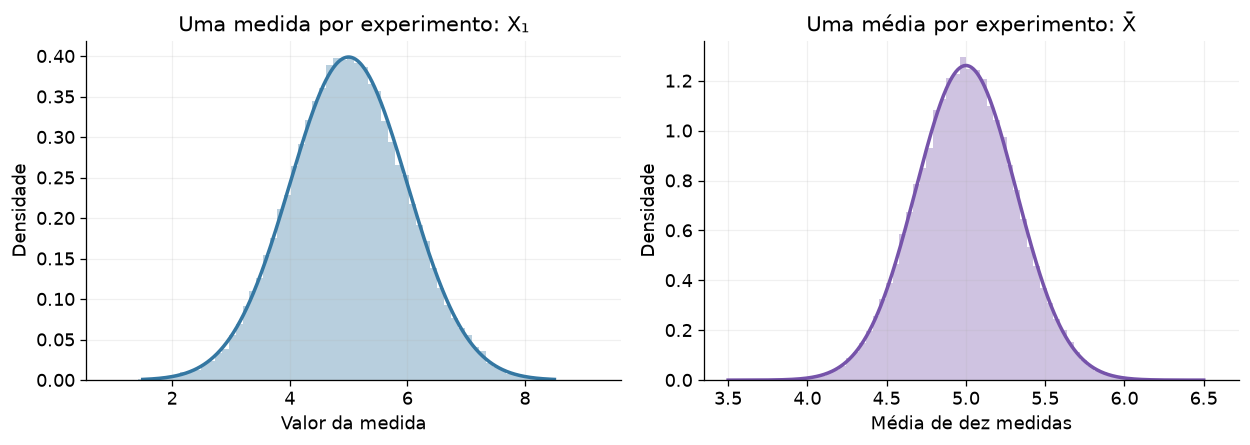

In [2]:
# R experimentos completos; cada linha contém n medidas.
mu, sigma, n, R = 5.0, 1.0, 10, 60000
amostras = rng.normal(mu, sigma, size=(R, n))
medias = amostras.mean(axis=1)
variancias = amostras.var(axis=1, ddof=1)
display(pd.DataFrame(amostras[:4], index=['experimento 1','experimento 2',
                                         'experimento 3','experimento 4'],
                     columns=[f'x{i+1}' for i in range(n)]))
print(f'Uma amostra: média = {medias[0]:.4f}; S² = {variancias[0]:.4f}')
fig, ax = plt.subplots(1,2,figsize=(11,4))
x = np.linspace(1.5,8.5,500)
ax[0].hist(amostras[:,0],bins=70,density=True,alpha=.35,color=CORES['azul'])
ax[0].plot(x,stats.norm.pdf(x,mu,sigma),color=CORES['azul'])
ax[0].set(title='Uma medida por experimento: X₁',xlabel='Valor da medida',ylabel='Densidade')
xm=np.linspace(3.5,6.5,500)
ax[1].hist(medias,bins=70,density=True,alpha=.35,color=CORES['roxo'])
ax[1].plot(xm,stats.norm.pdf(xm,mu,sigma/np.sqrt(n)),color=CORES['roxo'])
ax[1].set(title='Uma média por experimento: X̄',xlabel='Média de dez medidas',ylabel='Densidade')
figura(fig,'01_medida_e_media')
verificar('Média simulada: dentro de 5 erros de Monte Carlo',
          abs(medias.mean()-mu)<5*sigma/np.sqrt(n*R))
verificar('Variância das médias: σ²/n', abs(medias.var()-sigma**2/n)<.004)

### 1.3 As funções Gamma e Beta antes de utilizá-las

Vamos retomar apenas o necessário do capítulo 5. Para $a>0$,

$$\Gamma(a)=\int_0^\infty u^{a-1}e^{-u}\,du.$$

Integração por partes dá $\Gamma(a+1)=a\Gamma(a)$; portanto, $\Gamma(m+1)=m!$ para inteiro $m\geq0$. Também $\Gamma(1/2)=\sqrt\pi$, pela substituição $u=v^2$ e a integral gaussiana.

A função Beta, para $a,b>0$, é

$$B(a,b)=\int_0^1v^{a-1}(1-v)^{b-1}\,dv
=\frac{\Gamma(a)\Gamma(b)}{\Gamma(a+b)}.$$

Para ver a última igualdade, escrevemos $\Gamma(a)\Gamma(b)$ como uma integral dupla em $u,w>0$ e fazemos $r=u+w$, $v=u/(u+w)$. Assim $u=rv$, $w=r(1-v)$ e o módulo do jacobiano é $r$. A integral separa em $\Gamma(a+b)B(a,b)$. A função $B$ aparecerá na normalização de $F$; não precisamos antecipar nenhum resultado de inferência para defini-la.

Usaremos a Gamma na parametrização **forma–escala**:

$$Y\sim\operatorname{Gamma}(a,\theta),\qquad
f_Y(y)=\frac{y^{a-1}e^{-y/\theta}}{\Gamma(a)\theta^a},\quad y>0,$$

com $a>0$ adimensional e $\theta>0$ com as unidades de $Y$. Fazendo $u=y/\theta$, a normalização vira a integral que define $\Gamma(a)$. Os momentos são

$$\mathbb E[Y^r]=\theta^r\frac{\Gamma(a+r)}{\Gamma(a)},\quad r>-a,$$
$$\mathbb E[Y]=a\theta,\qquad\operatorname{Var}(Y)=a\theta^2.$$

Na SciPy, `stats.gamma(a, scale=theta)` usa essa convenção. A taxa seria $\lambda=1/\theta$; não vamos trocar escala por taxa no meio de uma conta.

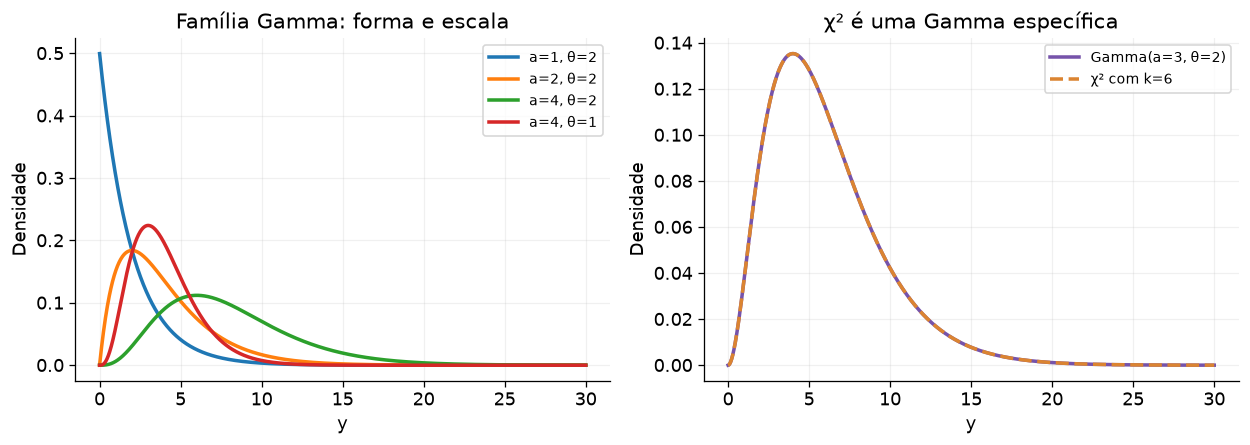

In [3]:
# Conferir a normalização por integração independente e a relação Gamma–Beta.
for a,b in [(0.5,0.5),(2.,3.),(3.5,1.7)]:
    integral=integrate.quad(lambda v:v**(a-1)*(1-v)**(b-1),0,1)[0]
    verificar(f'Beta integral a={a}, b={b}',np.isclose(integral,special.beta(a,b)))

fig,ax=plt.subplots(1,2,figsize=(11,4))
y=np.linspace(.002,30,1500)
for a,theta in [(1,2),(2,2),(4,2),(4,1)]:
    ax[0].plot(y,stats.gamma.pdf(y,a,scale=theta),label=f'a={a}, θ={theta}')
k=6
ax[1].plot(y,stats.gamma.pdf(y,k/2,scale=2),label='Gamma(a=3, θ=2)',color=CORES['roxo'])
ax[1].plot(y,stats.chi2.pdf(y,k),'--',label='χ² com k=6',color=CORES['laranja'])
for axt in ax:
    axt.set(xlabel='y',ylabel='Densidade');axt.legend(fontsize=9)
ax[0].set_title('Família Gamma: forma e escala')
ax[1].set_title('χ² é uma Gamma específica')
figura(fig,'02_gamma_e_chi2')
verificar('χ²_k = Gamma(k/2, escala 2)',np.allclose(stats.chi2.pdf(y,k),stats.gamma.pdf(y,k/2,scale=2)))

### 1.4 Teorema 1 — Soma de quadrados de gaussianas padronizadas — slides 58–60

**Hipóteses:** $X_i$ independentes, $X_i\sim\mathcal N(\mu,\sigma^2)$, $\sigma>0$. Definimos $Z_i=(X_i-\mu)/\sigma$, de modo que $Z_i\sim\mathcal N(0,1)$. Então

$$Q=\sum_{i=1}^nZ_i^2\sim\chi_n^2.$$

Os quadrados são não negativos e adimensionais. O número de componentes gaussianas independentes é o número de **graus de liberdade**, aqui $k=n$. A densidade é

$$f_Q(q;k)=\frac{q^{k/2-1}e^{-q/2}}{2^{k/2}\Gamma(k/2)},\qquad q>0.$$

Logo $\chi_k^2=\operatorname{Gamma}(k/2,2)$, $\mathbb E[Q]=k$, $\operatorname{Var}(Q)=2k$. A Gamma também permite definir essa família para $k>0$ não inteiro, embora a construção por $k$ quadrados use $k$ inteiro.

**Prova por função geradora de momentos.** Definimos $M_A(t)=\mathbb E[e^{tA}]$, quando existe numa vizinhança de zero. Para um quadrado,

$$M_{Z^2}(t)=\frac1{\sqrt{2\pi}}\int_{-\infty}^\infty
 e^{tz^2}e^{-z^2/2}\,dz
=\frac1{\sqrt{2\pi}}\int e^{-(1-2t)z^2/2}\,dz
=(1-2t)^{-1/2},\quad t<\tfrac12.$$

A última igualdade usa $u=\sqrt{1-2t}\,z$. Pela independência,

$$M_Q(t)=\prod_iM_{Z_i^2}(t)=(1-2t)^{-n/2}.$$

A integração da PDF Gamma fornece a mesma MGF: $M_Y(t)=(1-\theta t)^{-a}$. Como as MGFs existem perto de zero e coincidem, determinam a mesma distribuição. Assim temos o resultado, sem apenas reconhecer o formato do gráfico.

**Exemplo do slide 60.** $W_n=n(\bar X-\mu)^2/\sigma^2$ é exatamente $\chi_1^2$ para uma população normal, qualquer que seja $n$. Para uma população não normal com variância finita, o TLC dá $W_n\Rightarrow\chi_1^2$ quando $n\to\infty$. Os graus de liberdade são 1 porque aqui quadramos **uma** variável padronizada, a média; não são $n$.

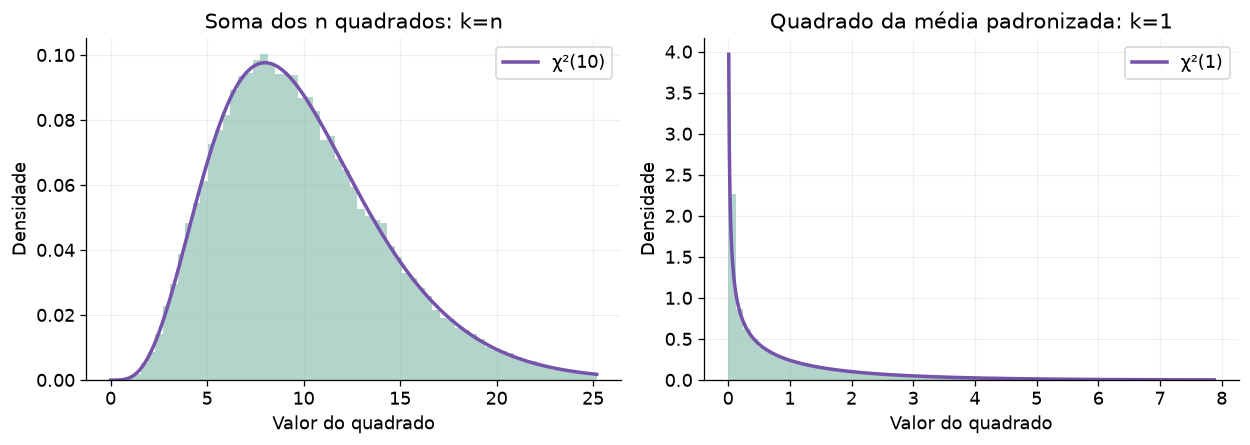

In [4]:
# Teorema 1: construir Q a partir das medidas, sem sortear diretamente de χ².
z=(amostras-mu)/sigma
q_total=np.sum(z**2,axis=1)
w_media=n*(medias-mu)**2/sigma**2
fig,ax=plt.subplots(1,2,figsize=(11,4))
for axt,dados,k,titulo in [(ax[0],q_total,n,'Soma dos n quadrados: k=n'),
                           (ax[1],w_media,1,'Quadrado da média padronizada: k=1')]:
    limite=stats.chi2.ppf(.995,k)
    xx=np.linspace(.01,limite,800)
    bordas=np.linspace(0,limite,66)
    largura=bordas[1]-bordas[0]
    # Densidade por classe: massa da classe dividida pela sua largura.
    # Os valores fora da janela continuam na normalização pelo total N.
    axt.hist(dados,bins=bordas,density=False,
             weights=np.full(len(dados),1/(len(dados)*largura)),
             alpha=.35,color=CORES['verde'])
    axt.plot(xx,stats.chi2.pdf(xx,k),color=CORES['roxo'],label=f'χ²({k})')
    axt.set(title=titulo,xlabel='Valor do quadrado',ylabel='Densidade');axt.legend()
figura(fig,'03_teorema_1')
verificar('Q: média n',abs(q_total.mean()-n)<.12)
verificar('Q: variância 2n',abs(q_total.var()-2*n)<.6)
verificar('W da média: média 1',abs(w_media.mean()-1)<.025)

### 1.5 $\chi^2$, $\chi$ e $\chi^2$ reduzido: três variáveis diferentes — slides 61–62

Para $Q\sim\chi_k^2$, definimos $C=\sqrt Q$ e $Q_{\mathrm{red}}=Q/k$. A distribuição de $C$ é chamada **chi**, sem o quadrado. Como $q=c^2$, o jacobiano é $dq/dc=2c$:

$$f_C(c)=2c\,f_Q(c^2)=\frac{2^{1-k/2}}{\Gamma(k/2)}c^{k-1}e^{-c^2/2},\quad c>0.$$

Geometricamente, $C$ é o comprimento de um vetor com $k$ componentes gaussianas padronizadas. Seus momentos são

$$\mathbb E[C^r]=2^{r/2}\frac{\Gamma((k+r)/2)}{\Gamma(k/2)},\qquad
\mathbb E[C]=\sqrt2\frac{\Gamma((k+1)/2)}{\Gamma(k/2)},\quad
\operatorname{Var}(C)=k-\mathbb E[C]^2.$$

Para o reduzido fazemos $q=ku$, logo

$$f_{Q_{\rm red}}(u)=k f_Q(ku),\qquad
\mathbb E[Q_{\rm red}]=1,\quad\operatorname{Var}(Q_{\rm red})=\frac2k.$$

Assim, quando $k$ aumenta, $Q$ se desloca para valores maiores e seu desvio padrão absoluto $\sqrt{2k}$ cresce; $Q_{\rm red}$ fica mais estreito em torno de 1. A dispersão **relativa** de $Q$ cai como $\sqrt{2/k}$. Uma “largura” precisa dizer qual escala estamos usando.

A forma também tende à gaussiana. Para $Z_i\sim\mathcal N(0,1)$, temos $\mathbb E[Z_i^2]=1$ e $\operatorname{Var}(Z_i^2)=2$, portanto o TLC dá

$$\frac{Q-k}{\sqrt{2k}}\Rightarrow\mathcal N(0,1).$$

A aproximação $Q\approx\mathcal N(k,2k)$ é útil para $k$ grande; para $k$ pequeno pode atribuir probabilidade a $Q<0$, algo impossível. Não usaremos essa aproximação para obter quantis exatos.

Para $k=1$, a densidade de $Q$ diverge quando $q\to0^+$, mas sua integral continua finita. Nos painéis de $\chi^2$ e de $\chi^2$ reduzido usaremos eixo vertical logarítmico para comparar também as densidades menores, sem cortar essa subida perto da origem. Um gráfico de densidade deve ser lido junto com sua escala.

Em um ajuste, um $\chi^2$ reduzido próximo de 1 é uma escala esperada sob um modelo e uma covariância adequados, não uma prova de que o modelo é correto. O resultado exato com graus de liberdade “número de dados menos parâmetros” exige condições, como um modelo linear de posto completo com erros gaussianos de covariância conhecida.

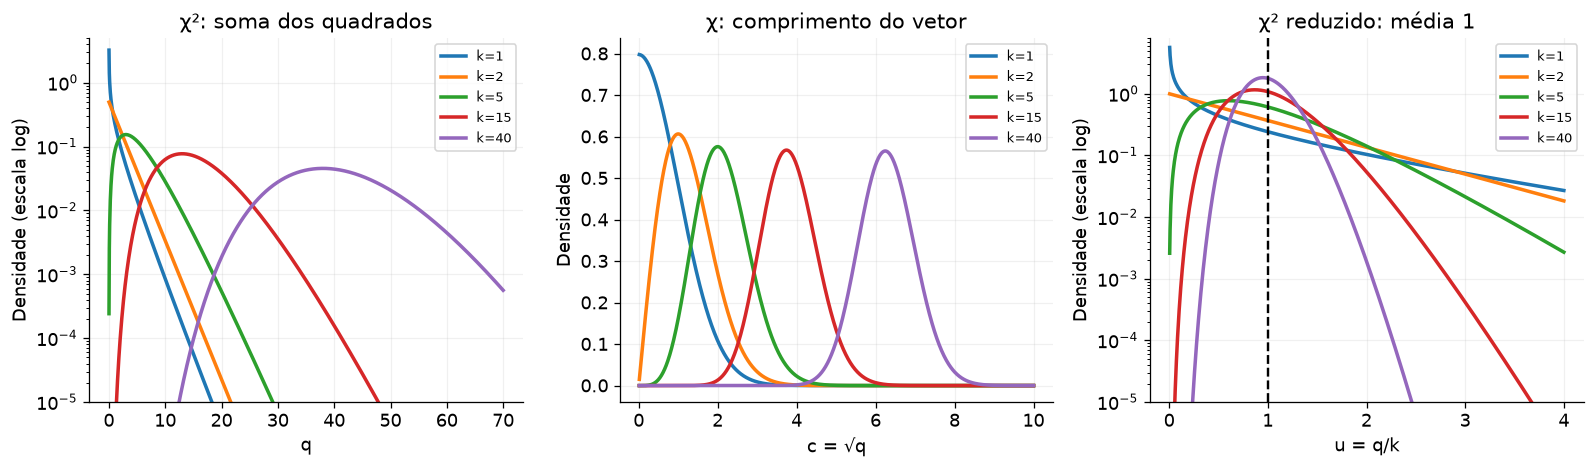

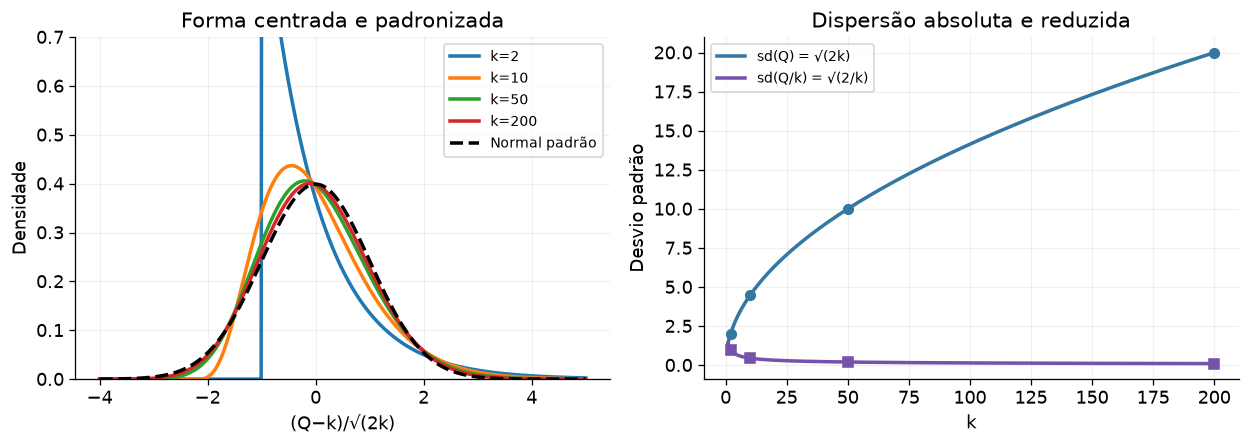

In [5]:
# Comparar as três variáveis; no reduzido, a linha marca a média 1.
ks=[1,2,5,15,40]
fig,ax=plt.subplots(1,3,figsize=(14,4.2))
for k in ks:
    q=np.linspace(.015,70,1200)
    c=np.linspace(.015,10,1000)
    u=np.linspace(.005,4,1000)
    ax[0].plot(q,stats.chi2.pdf(q,k),label=f'k={k}')
    ax[1].plot(c,stats.chi.pdf(c,k),label=f'k={k}')
    ax[2].plot(u,k*stats.chi2.pdf(k*u,k),label=f'k={k}')
    verificar(f'Jacobian da chi: k={k}',np.allclose(stats.chi.pdf(c,k),2*c*stats.chi2.pdf(c*c,k)))
ax[0].set(title='χ²: soma dos quadrados',xlabel='q',ylabel='Densidade (escala log)',yscale='log',ylim=(1e-5,5))
ax[1].set(title='χ: comprimento do vetor',xlabel='c = √q',ylabel='Densidade')
ax[2].set(title='χ² reduzido: média 1',xlabel='u = q/k',ylabel='Densidade (escala log)',yscale='log',ylim=(1e-5,8))
ax[2].axvline(1,color='black',ls='--',lw=1.5)
for axt in ax:axt.legend(fontsize=8)
figura(fig,'04_chi_chi2_reduzido')

fig,ax=plt.subplots(1,2,figsize=(11,4))
v=np.linspace(-4,5,1000)
for k in [2,10,50,200]:
    qq=k+np.sqrt(2*k)*v
    ax[0].plot(v,np.sqrt(2*k)*stats.chi2.pdf(qq,k),label=f'k={k}')
    ax[1].plot(k,np.sqrt(2*k),'o',color=CORES['azul'])
    ax[1].plot(k,np.sqrt(2/k),'s',color=CORES['roxo'])
ax[0].plot(v,stats.norm.pdf(v),'k--',label='Normal padrão')
ax[0].set(xlabel='(Q−k)/√(2k)',ylabel='Densidade',title='Forma centrada e padronizada',ylim=(0,.7));ax[0].legend(fontsize=9)
kg=np.linspace(1,200,400)
ax[1].plot(kg,np.sqrt(2*kg),label='sd(Q) = √(2k)',color=CORES['azul'])
ax[1].plot(kg,np.sqrt(2/kg),label='sd(Q/k) = √(2/k)',color=CORES['roxo'])
ax[1].set(xlabel='k',ylabel='Desvio padrão',title='Dispersão absoluta e reduzida');ax[1].legend(fontsize=9)
figura(fig,'05_chi2_limite_gaussiano')

### 1.6 Teorema 2 — Somar qui-quadrados independentes — slide 63

Se $Q_1\sim\chi_{k_1}^2$ e $Q_2\sim\chi_{k_2}^2$ são **independentes**, então

$$Q_1+Q_2\sim\chi_{k_1+k_2}^2.$$

De fato,

$$M_{Q_1+Q_2}(t)=M_{Q_1}(t)M_{Q_2}(t)
=(1-2t)^{-k_1/2}(1-2t)^{-k_2/2}
=(1-2t)^{-(k_1+k_2)/2}.$$

A soma concatena dois conjuntos de componentes independentes. Na linguagem da Gamma, somamos formas porque as escalas são iguais, ambas 2. Gammas de escalas distintas não têm, em geral, uma soma Gamma.

**Note que a independência faz parte da prova.** Se $Q_2=Q_1\sim\chi_3^2$, a soma é $2Q_1$: sua variância é $4\times6=24$, enquanto uma $\chi_6^2$ teria variância 12. A média, igual a 6 nos dois casos, não é suficiente para identificar a distribuição.

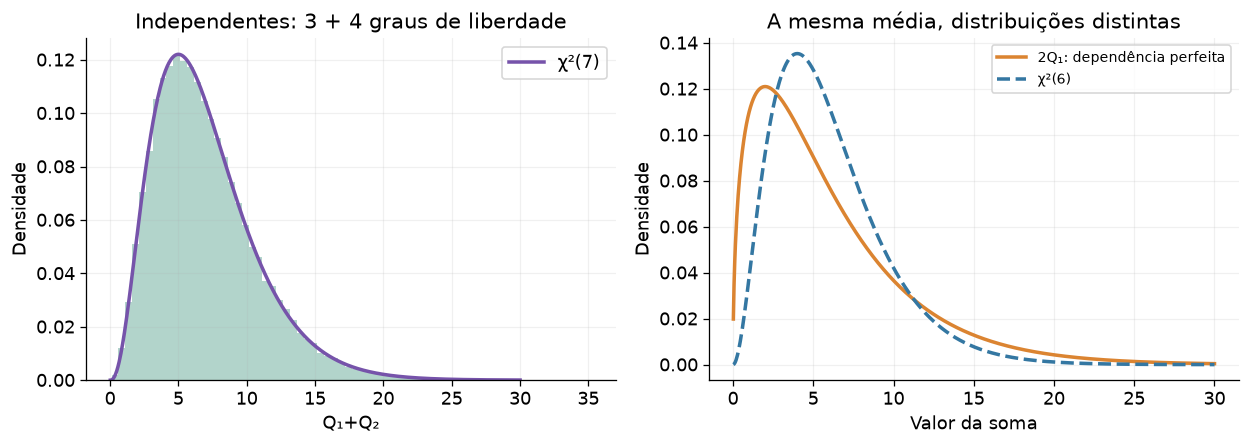

In [6]:
# Um caso correto e um caso em que a hipótese de independência falha.
q1=rng.chisquare(3,size=R)
q2=rng.chisquare(4,size=R)
fig,ax=plt.subplots(1,2,figsize=(11,4))
xx=np.linspace(.02,30,700)
ax[0].hist(q1+q2,bins=70,density=True,alpha=.35,color=CORES['verde'])
ax[0].plot(xx,stats.chi2.pdf(xx,7),color=CORES['roxo'],label='χ²(7)')
ax[0].set(title='Independentes: 3 + 4 graus de liberdade',xlabel='Q₁+Q₂',ylabel='Densidade');ax[0].legend()
ax[1].plot(xx,stats.chi2.pdf(xx/2,3)/2,label='2Q₁: dependência perfeita',color=CORES['laranja'])
ax[1].plot(xx,stats.chi2.pdf(xx,6),'--',label='χ²(6)',color=CORES['azul'])
ax[1].set(title='A mesma média, distribuições distintas',xlabel='Valor da soma',ylabel='Densidade');ax[1].legend(fontsize=9)
figura(fig,'06_teorema_2')
verificar('Soma independente: média 7',abs((q1+q2).mean()-7)<.10)
verificar('Soma independente: variância 14',abs((q1+q2).var()-14)<.6)

### 1.7 $S^2$: por que dividimos por $n-1$? — slides 64–67

Temos uma população IID com média $\mu$ e variância finita $\sigma^2$. Ambas podem ser desconhecidas. Para $n\geq2$,

$$S^2=\frac1{n-1}\sum_i(X_i-\bar X)^2,\qquad
S=\sqrt{S^2}.$$

$S^2$ tem as unidades de $X^2$ e $S$ as unidades de $X$. Os desvios em relação à média amostral obedecem $\sum_i(X_i-\bar X)=0$: se conhecemos $n-1$ deles, o último já está determinado.

Vamos abrir a identidade usada no livro. Como $X_i-\bar X=(X_i-\mu)-(\bar X-\mu)$,

$$\begin{aligned}
\sum_i(X_i-\bar X)^2
&=\sum_i(X_i-\mu)^2-2(\bar X-\mu)\sum_i(X_i-\mu)+n(\bar X-\mu)^2\\
&=\sum_i(X_i-\mu)^2-n(\bar X-\mu)^2,
\end{aligned}$$

pois $\sum_i(X_i-\mu)=n(\bar X-\mu)$. Tomando a esperança,

$$\mathbb E\!\left[\sum_i(X_i-\bar X)^2\right]
=n\sigma^2-n\operatorname{Var}(\bar X)
=n\sigma^2-\sigma^2=(n-1)\sigma^2.$$

Portanto, $\mathbb E[S^2]=\sigma^2$: **não enviesado** significa correto em média sobre amostras, não correto em cada amostra. Dividir por $n$ daria o estimador $V_n$, com $\mathbb E[V_n]=(n-1)\sigma^2/n$. Ele subestima em média porque a média escolhida dos próprios dados minimiza a soma dos quadrados.

Se $\mu$ é **conhecida**, usamos outra estatística,

$$S_\mu^2=\frac1n\sum_i(X_i-\mu)^2,\qquad \mathbb E[S_\mu^2]=\sigma^2.$$

Aqui não ajustamos a média aos dados. Não devemos dar o mesmo símbolo a essas duas regras sem avisar.

### 1.8 Teorema 3 — A distribuição de $S^2$ exige gaussianidade

Agora acrescentamos a hipótese $X_i\sim\mathcal N(\mu,\sigma^2)$ independentes. Então

$$U=\frac{(n-1)S^2}{\sigma^2}\sim\chi_{n-1}^2,\qquad
\bar X\ \text{é independente de}\ S^2.$$

A identidade anterior dá $Q=U+Z_0^2$, com $Z_0=\sqrt n(\bar X-\mu)/\sigma$. Mas **subtrair uma $\chi_1^2$ de uma $\chi_n^2$ não basta** para concluir o teorema. Falta justificar a distribuição dos componentes e sua independência.

**Prova completa por uma mudança de coordenadas.** Escreva $\mathbf Z=(Z_1,\ldots,Z_n)$, com densidade conjunta

$$f_{\mathbf Z}(\mathbf z)=(2\pi)^{-n/2}e^{-\|\mathbf z\|^2/2}.$$

Escolha uma matriz ortogonal $O$, cuja primeira linha é $(1,\ldots,1)/\sqrt n$, e defina $\mathbf W=O\mathbf Z$. “Ortogonal” significa $OO^T=I$: preserva comprimentos e tem módulo do determinante 1. Pela transformação de variáveis,

$$f_{\mathbf W}(\mathbf w)=(2\pi)^{-n/2}e^{-\|\mathbf w\|^2/2}
=\prod_{j=0}^{n-1}\frac{e^{-w_j^2/2}}{\sqrt{2\pi}}.$$

Logo os novos componentes também são normais padrão **independentes**. O primeiro é

$$W_0=\frac1{\sqrt n}\sum_iZ_i=\frac{\sqrt n(\bar X-\mu)}{\sigma}.$$

Como $\sum_iZ_i^2=\sum_jW_j^2$, a identidade dos quadrados fornece

$$U=Q-W_0^2=\sum_{j=1}^{n-1}W_j^2.$$

Pelo teorema 1, $U\sim\chi_{n-1}^2$. Ele depende só de $W_1,\ldots,W_{n-1}$ e é independente de $W_0$, portanto de $\bar X$. Esta é a justificativa que faltava no argumento abreviado.

Para $n=2$ a geometria é explícita: $W_0=(Z_1+Z_2)/\sqrt2$ e $W_1=(Z_1-Z_2)/\sqrt2$. A soma determina a média; a diferença determina a dispersão. Para gaussianas, essas duas direções são independentes.

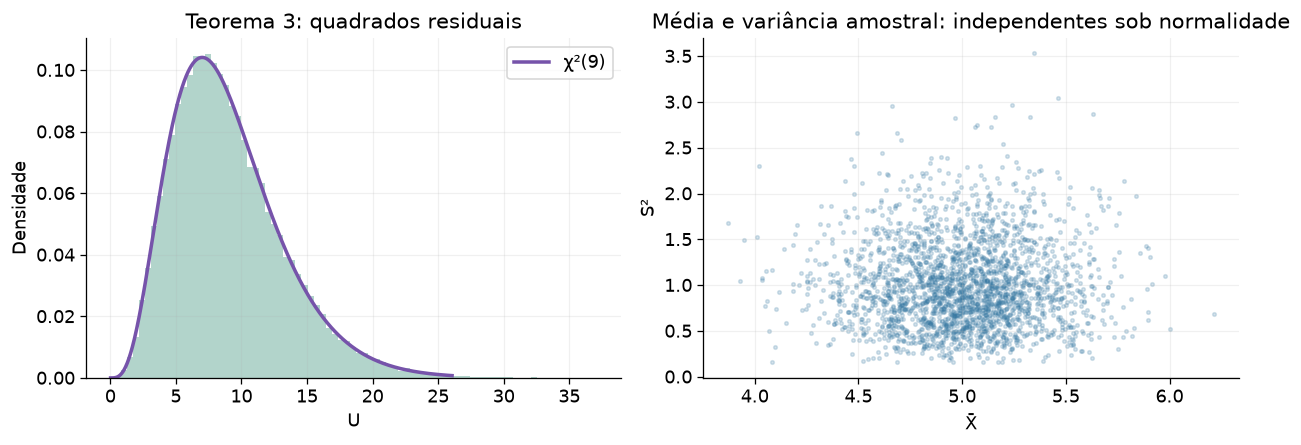

Correlação simulada X̄–S²: 0.0026
Correlação próxima de zero é ilustrativa; a prova de independência foi a fatoração da densidade.


In [7]:
# Construir as coordenadas ortogonais usando uma base do subespaço de soma zero.
e=np.ones(n)/np.sqrt(n)
base_residual=linalg.null_space(e.reshape(1,-1)).T
O=np.vstack([e,base_residual])
w=z@O.T
u=(n-1)*variancias/sigma**2
verificar('Matriz ortogonal',np.allclose(O@O.T,np.eye(n)))
verificar('Primeira coordenada = média padronizada',np.allclose(w[:,0],np.sqrt(n)*(medias-mu)/sigma))
verificar('Soma residual = (n−1)S²/σ²',np.allclose((w[:,1:]**2).sum(axis=1),u))
verificar('Identidade Q = U + W₀²',np.allclose(q_total,u+w_media))
fig,ax=plt.subplots(1,2,figsize=(11,4))
xx=np.linspace(.02,stats.chi2.ppf(.998,n-1),800)
ax[0].hist(u,bins=80,density=True,alpha=.35,color=CORES['verde'])
ax[0].plot(xx,stats.chi2.pdf(xx,n-1),label=f'χ²({n-1})',color=CORES['roxo'])
ax[0].set(title='Teorema 3: quadrados residuais',xlabel='U',ylabel='Densidade');ax[0].legend()
ax[1].scatter(medias[:2500],variancias[:2500],s=5,alpha=.2,color=CORES['azul'])
ax[1].set(title='Média e variância amostral: independentes sob normalidade',
          xlabel='X̄',ylabel='S²')
figura(fig,'07_teorema_3_geometria')
print(f'Correlação simulada X̄–S²: {np.corrcoef(medias,variancias)[0,1]:.4f}')
print('Correlação próxima de zero é ilustrativa; a prova de independência foi a fatoração da densidade.')

### 1.9 A distribuição de $S^2$ e a distribuição de $S$

Escreva $\nu=n-1$. Pelo teorema 3,

$$S^2=\frac{\sigma^2}{\nu}U\sim
\operatorname{Gamma}\!\left(\frac\nu2,\frac{2\sigma^2}{\nu}\right),$$
$$f_{S^2}(v)=\frac{\nu}{\sigma^2}f_{\chi_\nu^2}\!\left(\frac{\nu v}{\sigma^2}\right),\quad v>0,$$
$$\mathbb E[S^2]=\sigma^2,\qquad
\operatorname{Var}(S^2)=\frac{2\sigma^4}{\nu}.$$

Para o desvio padrão, $S=\sigma\sqrt{U/\nu}$ é uma chi reescalada:

$$f_S(s)=\frac{\sqrt\nu}{\sigma}f_{\chi_\nu}\!\left(\frac{\sqrt\nu\,s}{\sigma}\right),\quad s>0,$$
$$\mathbb E[S]=\sigma c_4(n),\qquad
c_4(n)=\sqrt{\frac2\nu}\frac{\Gamma((\nu+1)/2)}{\Gamma(\nu/2)}<1,$$
$$\operatorname{Var}(S)=\sigma^2[1-c_4(n)^2].$$

$S^2$ é não enviesado, mas $S$ não é: a raiz quadrada é não linear. Pela concavidade da raiz, $\mathbb E[\sqrt{S^2}]<\sqrt{\mathbb E[S^2]}=\sigma$ quando a variância amostral não é constante. O fator $c_4$ acima é específico do modelo gaussiano.

O **erro padrão estimado da média** é $S/\sqrt n$. Ele estima a escala $\sigma/\sqrt n$ da distribuição de $\bar X$. Não é a dispersão das medidas individuais e, sozinho, não é um intervalo de confiança. Para construir o intervalo ainda precisamos de um quantil e de suas hipóteses.

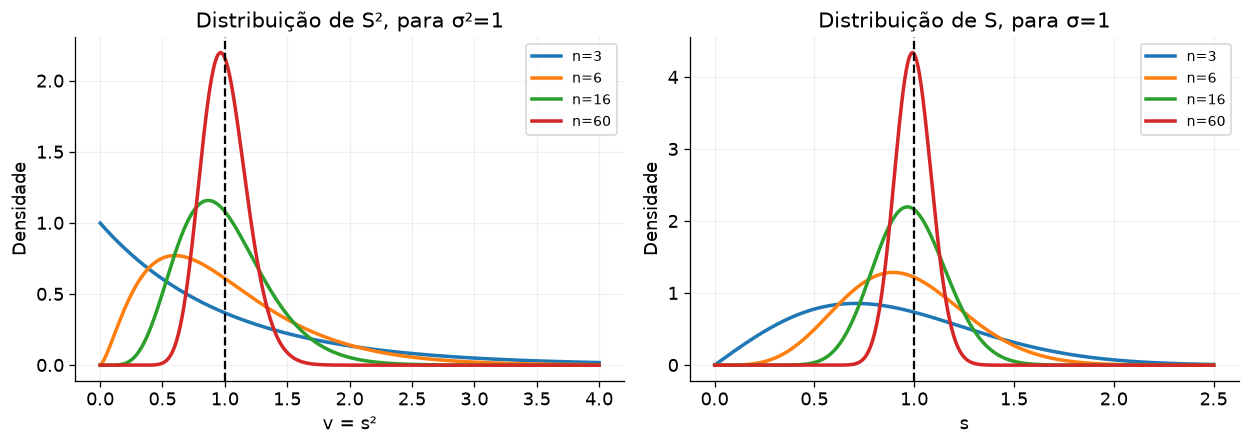

,n,E[S]/σ = c₄,Var(S²)/σ⁴,Var(S)/σ²
0,3,0.88623,1.00000,0.21460
1,6,0.95153,0.40000,0.09459
2,16,0.98348,0.13333,0.03276
3,60,0.99577,0.03390,0.00844


In [8]:
# Ver como a distribuição dos estimadores estreita quando n aumenta.
fig,ax=plt.subplots(1,2,figsize=(11,4))
v=np.linspace(.001,4,900)
sgrid=np.linspace(.001,2.5,900)
linhas=[]
for ni in [3,6,16,60]:
    nu=ni-1
    c4=np.sqrt(2/nu)*np.exp(special.gammaln((nu+1)/2)-special.gammaln(nu/2))
    ax[0].plot(v,nu*stats.chi2.pdf(nu*v,nu),label=f'n={ni}')
    ax[1].plot(sgrid,np.sqrt(nu)*stats.chi.pdf(np.sqrt(nu)*sgrid,nu),label=f'n={ni}')
    linhas.append([ni,c4,2/nu,1-c4*c4])
for axt in ax:
    axt.axvline(1,color='black',ls='--',lw=1.4);axt.legend(fontsize=9);axt.set_ylabel('Densidade')
ax[0].set(title='Distribuição de S², para σ²=1',xlabel='v = s²')
ax[1].set(title='Distribuição de S, para σ=1',xlabel='s')
figura(fig,'08_distribuicoes_S2_S')
display(pd.DataFrame(linhas,columns=['n','E[S]/σ = c₄','Var(S²)/σ⁴','Var(S)/σ²']))

### 1.10 Não enviesado não significa distribuído como qui-quadrado

A prova de $\mathbb E[S^2]=\sigma^2$ usou apenas independência, igualdade das distribuições e variância finita. A prova da distribuição $\chi^2$ e da independência entre $\bar X$ e $S^2$ usou a **densidade conjunta gaussiana**. O TLC para a média não torna automaticamente esses resultados exatos para a variância.

Vamos comparar uma normal, uma uniforme e uma exponencial, todas com variância 1. No exemplo exponencial a assimetria cria uma associação forte entre média e variância amostral. Todas devem dar $\mathbb E[S^2]\approx1$, mas os histogramas de $U$ serão diferentes.

Para distribuições IID com quarto momento central finito $\mu_4=\mathbb E[(X-\mu)^4]$, a expansão dos produtos da soma de quadrados dá

$$\operatorname{Var}(S^2)=\frac1n\left[\mu_4-\frac{n-3}{n-1}\sigma^4\right].$$

Essa fórmula conecta a dispersão de $S^2$ à kurtosis do capítulo 5: a normal tem $\mu_4=3\sigma^4$ e recupera $2\sigma^4/(n-1)$. Caudas e quarto momento importam para a variância de uma estimativa de variância. Nos intervalos exatos deste capítulo, manteremos a hipótese normal explícita.

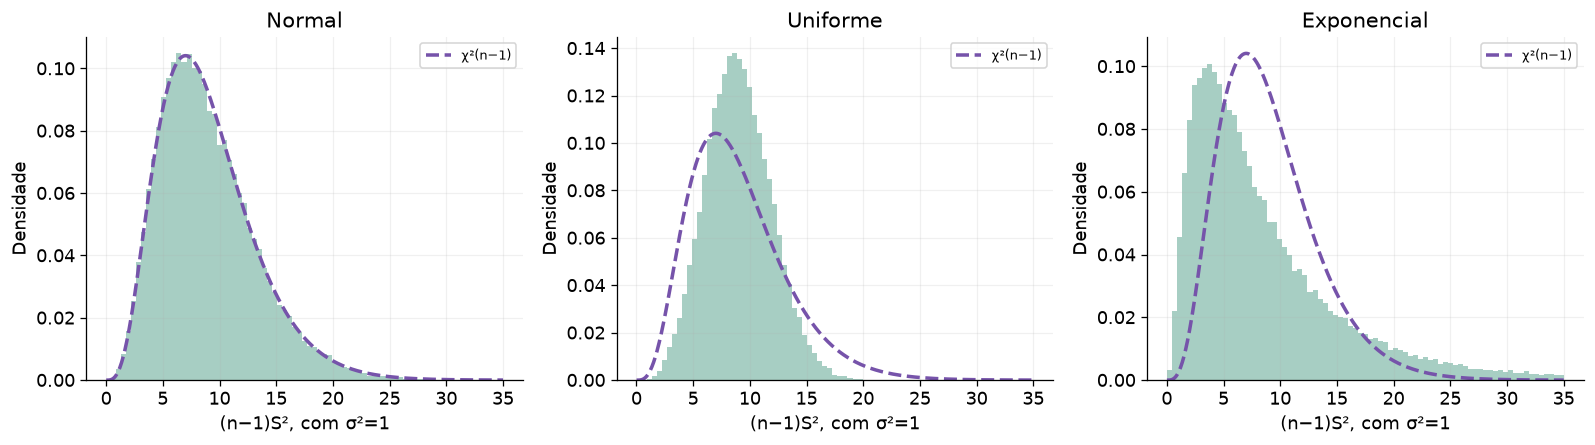

,População,Média de S²,Média com divisor n,Correlação X̄–S²
0,Normal,0.99685,0.89716,-0.00192
1,Uniforme,1.00214,0.90192,0.00849
2,Exponencial,1.00294,0.90265,0.69769


In [9]:
# A média de S² continua correta; sua forma amostral muda.
modelos={'Normal':rng.normal(size=(R,n)),
         'Uniforme':rng.uniform(-np.sqrt(3),np.sqrt(3),size=(R,n)),
         'Exponencial':rng.exponential(size=(R,n))}
fig,ax=plt.subplots(1,3,figsize=(14,4))
linhas=[]
xx=np.linspace(.01,35,700)
for axt,(nome,dados) in zip(ax,modelos.items()):
    m=dados.mean(axis=1);s2=dados.var(axis=1,ddof=1)
    axt.hist((n-1)*s2,bins=np.linspace(0,35,80),density=True,alpha=.4,color=CORES['verde'])
    axt.plot(xx,stats.chi2.pdf(xx,n-1),'--',color=CORES['roxo'],label='χ²(n−1)')
    axt.set(title=nome,xlabel='(n−1)S², com σ²=1',ylabel='Densidade');axt.legend(fontsize=8)
    linhas.append([nome,s2.mean(),(s2*(n-1)/n).mean(),np.corrcoef(m,s2)[0,1]])
    verificar(f'S² não enviesado, {nome}',abs(s2.mean()-1)<.045)
figura(fig,'09_S2_normalidade')
display(pd.DataFrame(linhas,columns=['População','Média de S²','Média com divisor n','Correlação X̄–S²']))

### 1.11 Exercício indicado no slide 67 — Gregory, pp. 145–147

Amostras gaussianas de tamanho $n=16$, com média e variância desconhecidas. Queremos interpretar e calcular

$$P_{\mu,\sigma}(\sigma^2<0.49S^2).$$

O subscrito lembra que $\mu,\sigma$ são fixos no experimento. O evento é aleatório porque **$S^2$ varia entre amostras**. Isso não é uma posterior para $\sigma^2$ depois de observar $s^2$.

Invertendo a desigualdade positiva,

$$\sigma^2<0.49S^2
\iff\frac{S^2}{\sigma^2}>\frac1{0.49}
\iff U=\frac{15S^2}{\sigma^2}>\frac{15}{0.49}=30.612244\ldots.$$

Pelo teorema 3, $U\sim\chi_{15}^2$. Portanto,

$$P_{\mu,\sigma}(\sigma^2<0.49S^2)
=\int_{30.612244\ldots}^{\infty}
\frac{u^{15/2-1}e^{-u/2}}{2^{15/2}\Gamma(15/2)}\,du\approx0.01.$$

A interpretação: em aproximadamente 1% das amostras, $S^2$ superestima a variância tanto que $0.49S^2$ ainda excede $\sigma^2$. Se já observamos um valor $s^2$, não podemos reapresentar essa conta como $P(\sigma^2<0.49s^2\mid D)=1\%$ sem fazer inferência bayesiana.

Para uma cauda numérica usamos a **survival function**, `sf(q)=P(U>q)`, evitando perder precisão ao subtrair uma CDF muito próxima de 1.

Limite = 30.612245; cauda exata = 0.009896; Monte Carlo = 0.009685
Quantil de 99%: 30.577914


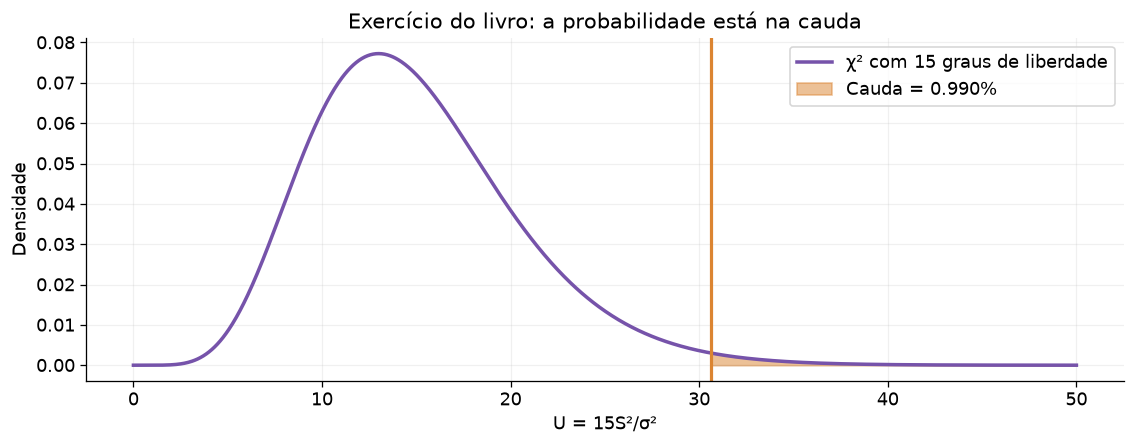

In [10]:
nu_ex=15
limite=nu_ex/.49
p_ex=stats.chi2.sf(limite,nu_ex)
p_quad=integrate.quad(lambda u:stats.chi2.pdf(u,nu_ex),limite,np.inf)[0]
u_ex_sim=rng.chisquare(nu_ex,size=200000)
p_sim=np.mean(u_ex_sim>limite)
print(f'Limite = {limite:.6f}; cauda exata = {p_ex:.6f}; Monte Carlo = {p_sim:.6f}')
print(f'Quantil de 99%: {stats.chi2.ppf(.99,nu_ex):.6f}')
fig,ax=plt.subplots(figsize=(10,4))
xx=np.linspace(.001,50,1000);dens=stats.chi2.pdf(xx,nu_ex)
ax.plot(xx,dens,color=CORES['roxo'],label='χ² com 15 graus de liberdade')
ax.fill_between(xx,dens,where=xx>=limite,color=CORES['laranja'],alpha=.5,label=f'Cauda = {p_ex:.3%}')
ax.axvline(limite,color=CORES['laranja'],lw=2)
ax.set(xlabel='U = 15S²/σ²',ylabel='Densidade',title='Exercício do livro: a probabilidade está na cauda');ax.legend()
figura(fig,'10_exercicio_S2_gregory')
verificar('Cauda χ² por integral independente',np.isclose(p_ex,p_quad,rtol=1e-8))
verificar('Cauda χ² simulada',abs(p_sim-p_ex)<5*np.sqrt(p_ex*(1-p_ex)/len(u_ex_sim)))

### 1.12 Teorema 4 — De onde vem a Student? — slides 68–69

**Hipóteses:** $Z\sim\mathcal N(0,1)$, $U\sim\chi_\nu^2$, $\nu>0$, e $Z,U$ independentes. Definimos

$$T=\frac{Z}{\sqrt{U/\nu}}.$$

O denominador agora é aleatório. Se $U/\nu$ fica pequeno em uma amostra, a razão pode ser grande. Esse mecanismo produz caudas mais pesadas que as de uma normal.

**Prova por transformação de duas variáveis.** Mantemos $u$ e trocamos $z$ por $t$: $z=t\sqrt{u/\nu}$. O módulo do jacobiano de $(t,u)\mapsto(z,u)$ é $\sqrt{u/\nu}$. Pela independência,

$$f_{T,U}(t,u)=f_Z\!\left(t\sqrt{u/\nu}\right)f_U(u)\sqrt{u/\nu}.$$

Marginalizamos $u>0$:

$$\begin{aligned}
f_T(t)&=\frac{1}{\sqrt{2\pi\nu}\,2^{\nu/2}\Gamma(\nu/2)}
\int_0^\infty u^{(\nu+1)/2-1}
\exp\!\left[-\frac{u}{2}\left(1+\frac{t^2}{\nu}\right)\right]du.
\end{aligned}$$

Para $a,c>0$, $\int_0^\infty u^{a-1}e^{-cu}du=\Gamma(a)c^{-a}$, pela substituição $v=cu$. Usando $a=(\nu+1)/2$ e $c=(1+t^2/\nu)/2$, chegamos a

$$\boxed{f_T(t;\nu)=\frac{\Gamma((\nu+1)/2)}{\sqrt{\pi\nu}\Gamma(\nu/2)}
\left(1+\frac{t^2}{\nu}\right)^{-(\nu+1)/2}},\quad -\infty<t<\infty.$$

**Onde entrou a independência?** Na fatoração $f_{Z,U}=f_Zf_U$. Sem ela, ter essas duas marginais não determina a distribuição da razão.

**Momentos e limite.** A densidade é simétrica, mas sua média só existe se $\nu>1$. Para $\nu=1$, é uma Cauchy e o “centro zero” não é uma esperança finita. Para $\nu>2$,

$$\mathbb E[T]=0,\qquad
\operatorname{Var}(T)=\mathbb E[Z^2]\nu\mathbb E[U^{-1}]
=\frac{\nu}{\nu-2},$$

porque $\mathbb E[U^{-1}]=\tfrac12\Gamma(\nu/2-1)/\Gamma(\nu/2)=1/(\nu-2)$. Para $1<\nu\leq2$, a média existe e a variância diverge. Como $\mathbb E[U/\nu]=1$ e $\operatorname{Var}(U/\nu)=2/\nu$, o denominador converge em probabilidade para 1; a razão converge em distribuição à normal padrão.

Na amostra normal, o teorema 3 fornece exatamente os componentes independentes:

$$Z=\frac{\bar X-\mu}{\sigma/\sqrt n},\qquad
U=\frac{(n-1)S^2}{\sigma^2},\qquad\nu=n-1.$$

Substituindo, a escala desconhecida cancela:

$$T=\frac{(\bar X-\mu)/(\sigma/\sqrt n)}{S/\sigma}
=\frac{\bar X-\mu}{S/\sqrt n}\sim t_{n-1}.$$

É essa **razão**, e não $\bar X$ isoladamente, que tem distribuição Student. A distribuição de $\bar X$ continua normal sob a população normal, mesmo quando nós não conhecemos $\sigma$.

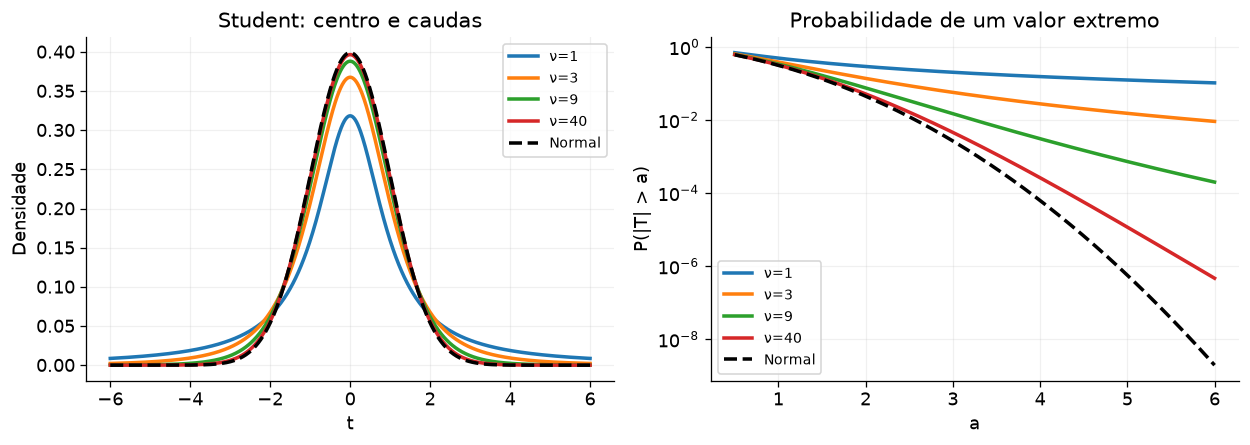

In [11]:
# Conferir a prova integrando a densidade conjunta transformada.
def densidade_t_por_integral(t,nu):
    # Integrar em a=√(u/ν) torna a integral regular na origem.
    integrando=lambda a:stats.norm.pdf(t*a)*stats.chi2.pdf(nu*a*a,nu)*2*nu*a*a
    return integrate.quad(integrando,0,np.inf,epsabs=1e-10)[0]
for nu_i in [1,3,9]:
    for ti in [0.,1.2,3.]:
        verificar(f'Student pela integral: ν={nu_i}, t={ti}',
                  np.isclose(densidade_t_por_integral(ti,nu_i),stats.t.pdf(ti,nu_i),rtol=1e-7))

fig,ax=plt.subplots(1,2,figsize=(11,4))
tg=np.linspace(-6,6,1200)
for nu_i in [1,3,9,40]:
    ax[0].plot(tg,stats.t.pdf(tg,nu_i),label=f'ν={nu_i}')
    cauda=2*stats.t.sf(np.linspace(.5,6,500),nu_i)
    ax[1].semilogy(np.linspace(.5,6,500),cauda,label=f'ν={nu_i}')
ax[0].plot(tg,stats.norm.pdf(tg),'k--',label='Normal')
ax[1].semilogy(np.linspace(.5,6,500),2*stats.norm.sf(np.linspace(.5,6,500)),'k--',label='Normal')
ax[0].set(title='Student: centro e caudas',xlabel='t',ylabel='Densidade')
ax[1].set(title='Probabilidade de um valor extremo',xlabel='a',ylabel='P(|T| > a)')
for axt in ax:axt.legend(fontsize=9)
figura(fig,'11_student_e_caudas')

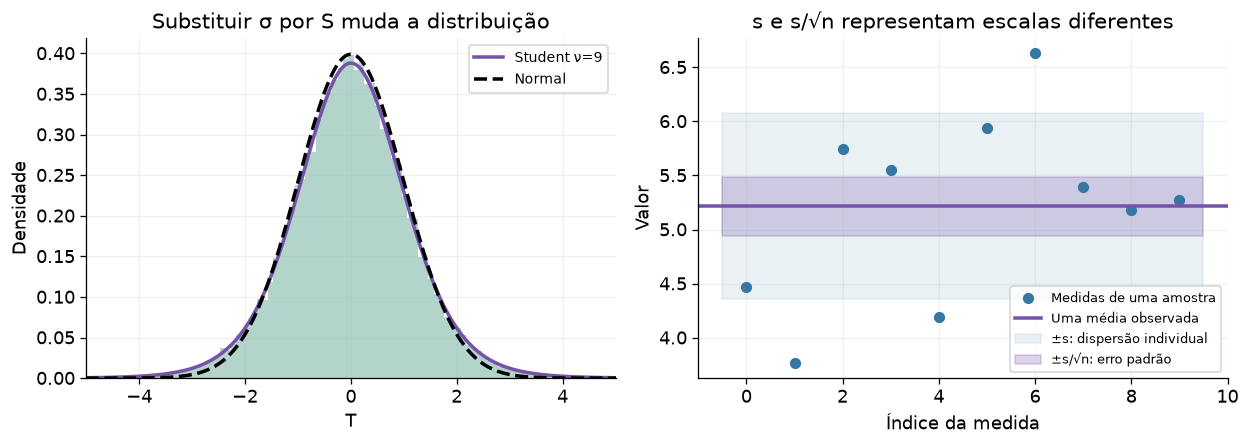

In [12]:
# Agora construir T da própria amostra: média e S variam juntos entre experimentos.
t_amostral=(medias-mu)/(np.sqrt(variancias)/np.sqrt(n))
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].hist(t_amostral,bins=np.linspace(-5,5,100),density=True,alpha=.35,color=CORES['verde'])
ax[0].plot(tg,stats.t.pdf(tg,n-1),label=f'Student ν={n-1}',color=CORES['roxo'])
ax[0].plot(tg,stats.norm.pdf(tg),'k--',label='Normal');ax[0].set(xlim=(-5,5),xlabel='T',ylabel='Densidade',title='Substituir σ por S muda a distribuição');ax[0].legend(fontsize=9)
ax[1].plot(amostras[0],'o',color=CORES['azul'],label='Medidas de uma amostra')
ax[1].axhline(medias[0],color=CORES['roxo'],label='Uma média observada')
s_obs=np.sqrt(variancias[0]);se_obs=s_obs/np.sqrt(n)
ax[1].fill_between([-0.5,n-.5],medias[0]-s_obs,medias[0]+s_obs,color=CORES['azul'],alpha=.1,label='±s: dispersão individual')
ax[1].fill_between([-0.5,n-.5],medias[0]-se_obs,medias[0]+se_obs,color=CORES['roxo'],alpha=.25,label='±s/√n: erro padrão')
ax[1].set(xlabel='Índice da medida',ylabel='Valor',title='s e s/√n representam escalas diferentes');ax[1].legend(fontsize=8)
figura(fig,'12_student_amostral_erro_padrao')
verificar('Student simulada: variância ν/(ν−2)',abs(t_amostral.var()-(n-1)/(n-3))<.06)

### 1.13 Exemplo da Student no Gregory — pp. 148–149

O livro usa $n=16$, $\bar x=0.75\,{\rm mg}$, $s=0.197\,{\rm mg}$ e uma referência $\mu_0=0.6\,{\rm mg}$. Sob medidas IID normais,

$$t_{\rm obs}=\frac{0.75-0.6}{0.197/\sqrt{16}}=3.0457\ldots,\qquad \nu=15.$$

A diferença é menor que um desvio padrão **individual**, mas é cerca de três erros padrão **da média**. A cauda unilateral $P_{\mu_0}(T\geq t_{\rm obs})$ é aproximadamente $0.4\%$. A probabilidade de um ponto exato é zero em uma distribuição contínua; a área de cauda responde a outra pergunta.

Esse número é uma probabilidade sobre possíveis amostras **condicionada à referência**, não a probabilidade de a afirmação sobre $\mu$ ser verdadeira. A interpretação como teste será aprofundada no capítulo 7. Aqui queremos entender a estatística e sua escala.

t observado = 3.045685; erro padrão = 0.049250 mg
Cauda unilateral = 0.004088


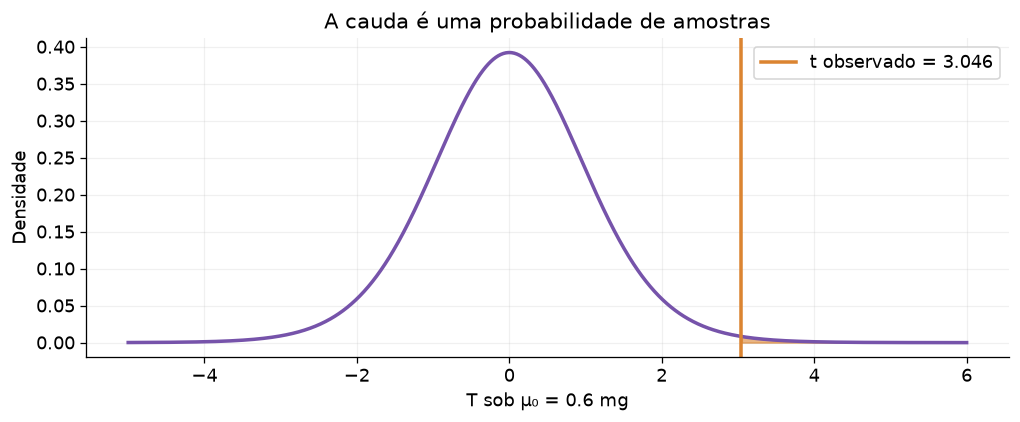

In [13]:
n_nic,xb_nic,s_nic,mu0_nic=16,.75,.197,.6
valor_t=(xb_nic-mu0_nic)/(s_nic/np.sqrt(n_nic))
print(f't observado = {valor_t:.6f}; erro padrão = {s_nic/np.sqrt(n_nic):.6f} mg')
print(f'Cauda unilateral = {stats.t.sf(valor_t,n_nic-1):.6f}')
fig,ax=plt.subplots(figsize=(9,3.8))
xx=np.linspace(-5,6,1000);yy=stats.t.pdf(xx,n_nic-1)
ax.plot(xx,yy,color=CORES['roxo'])
ax.fill_between(xx,yy,where=xx>=valor_t,color=CORES['laranja'],alpha=.6)
ax.axvline(valor_t,color=CORES['laranja'],label=f't observado = {valor_t:.3f}')
ax.set(xlabel='T sob μ₀ = 0.6 mg',ylabel='Densidade',title='A cauda é uma probabilidade de amostras');ax.legend()
figura(fig,'13_exemplo_student_gregory')

### 1.14 Teorema 5 — Razão de qui-quadrados e distribuição $F$ — slide 70

Se $U\sim\chi_{\nu_1}^2$ e $V\sim\chi_{\nu_2}^2$ são independentes, definimos

$$F=\frac{U/\nu_1}{V/\nu_2},\qquad \nu_1,\nu_2>0.$$

**Prova.** Mantenha $v$ e escreva $u=f(\nu_1/\nu_2)v$. Chamando $c=\nu_1/\nu_2$, o jacobiano é $cv$. Se $a=\nu_1/2$, $b=\nu_2/2$,

$$f_F(f)=\int_0^\infty f_U(cfv)f_V(v)cv\,dv
=\frac{c^af^{a-1}}{2^{a+b}\Gamma(a)\Gamma(b)}
\int_0^\infty v^{a+b-1}e^{-v(1+cf)/2}\,dv.$$

A mesma integral Gamma da prova da Student resulta em

$$\boxed{f_F(f)=\frac{c^a}{B(a,b)}\frac{f^{a-1}}{(1+cf)^{a+b}}},\quad f>0.$$

A ordem dos graus de liberdade importa: $\nu_1$ pertence ao numerador e $\nu_2$ ao denominador. Invertendo a razão, $1/F\sim F_{\nu_2,\nu_1}$.

Pela independência, $\mathbb E[F^r]=c^{-r}\Gamma(a+r)\Gamma(b-r)/[\Gamma(a)\Gamma(b)]$, para $-a<r<b$. Assim,

$$\mathbb E[F]=\frac{\nu_2}{\nu_2-2}\quad(\nu_2>2),$$
$$\operatorname{Var}(F)=\frac{2\nu_2^2(\nu_1+\nu_2-2)}{\nu_1(\nu_2-2)^2(\nu_2-4)}\quad(\nu_2>4).$$

A média de uma razão não é a razão das médias: embora $\mathbb E[U/\nu_1]=\mathbb E[V/\nu_2]=1$, $\mathbb E[F]>1$ quando existe. O denominador aleatório cria a assimetria. O livro impresso apresenta $(\nu_2-1)^2$ na equação 6.38; a dedução pelos momentos acima fornece $(\nu_2-2)^2$.

Para duas amostras normais **independentes**, de tamanhos $n_x,n_y$, usamos $\nu_1=n_x-1$ e $\nu_2=n_y-1$. Então

$$\frac{S_x^2/\sigma_x^2}{S_y^2/\sigma_y^2}\sim F_{\nu_1,\nu_2}.$$

Sob variâncias iguais, $S_x^2/S_y^2$ tem essa distribuição. Para variâncias diferentes, a razão observada precisa ser dividida pela razão populacional $\rho=\sigma_x^2/\sigma_y^2$ para formar o pivô.

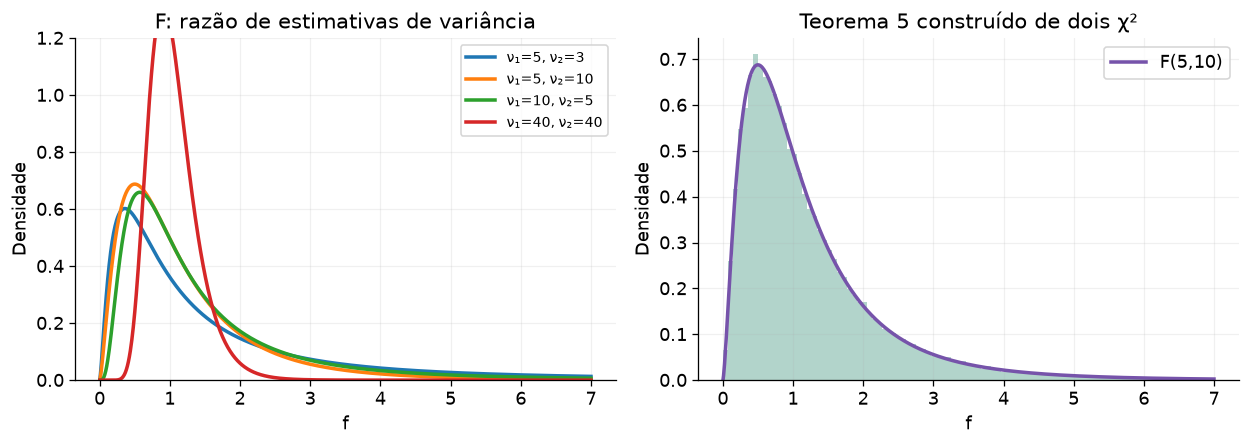

In [14]:
# Distribuição F: o denominador controla as caudas.
fig,ax=plt.subplots(1,2,figsize=(11,4))
fg=np.linspace(.003,7,1000)
for d1,d2 in [(5,3),(5,10),(10,5),(40,40)]:
    ax[0].plot(fg,stats.f.pdf(fg,d1,d2),label=f'ν₁={d1}, ν₂={d2}')
ax[0].set(xlabel='f',ylabel='Densidade',title='F: razão de estimativas de variância',ylim=(0,1.2));ax[0].legend(fontsize=9)
d1,d2=5,10
f_sim=(rng.chisquare(d1,R)/d1)/(rng.chisquare(d2,R)/d2)
ax[1].hist(f_sim,bins=np.linspace(0,7,100),density=True,alpha=.35,color=CORES['verde'])
ax[1].plot(fg,stats.f.pdf(fg,d1,d2),color=CORES['roxo'],label='F(5,10)')
ax[1].set(xlabel='f',ylabel='Densidade',title='Teorema 5 construído de dois χ²');ax[1].legend()
figura(fig,'14_teorema_5_F')
verificar('F: momento médio analítico',np.isclose(stats.f.mean(d1,d2),d2/(d2-2)))
verificar('F: variância analítica',np.isclose(stats.f.var(d1,d2),2*d2*d2*(d1+d2-2)/(d1*(d2-2)**2*(d2-4))))
for fi in [.2,1.,3.]:
    verificar(f'Inversão da F, f={fi}',np.isclose(stats.f.sf(fi,d1,d2),stats.f.cdf(1/fi,d2,d1)))

### 1.15 Exemplo do Gregory: duas variâncias — pp. 150–151

Os dados resumidos são $s_x^2=16.65$, $n_x=6$, $s_y^2=5.0$, $n_y=11$. Sob populações normais independentes e **a referência** $\sigma_x^2=\sigma_y^2$,

$$f_{\rm obs}=\frac{16.65}{5}=3.33,\qquad \nu_1=5,\ \nu_2=10.$$

Calcularemos a cauda $P(F\geq3.33)\approx5\%$. Se invertermos os nomes das amostras, o mesmo evento vira $P(F_{10,5}\leq1/3.33)$. Essa inversão troca a cauda e os graus de liberdade, preservando a probabilidade.

Não é uma probabilidade posterior de as variâncias serem iguais. Na parte 2 vamos usar o mesmo pivô para obter um intervalo para a razão $\rho$.

Razão observada = 3.3300; cauda = 0.049831
Evento invertido: 0.049831


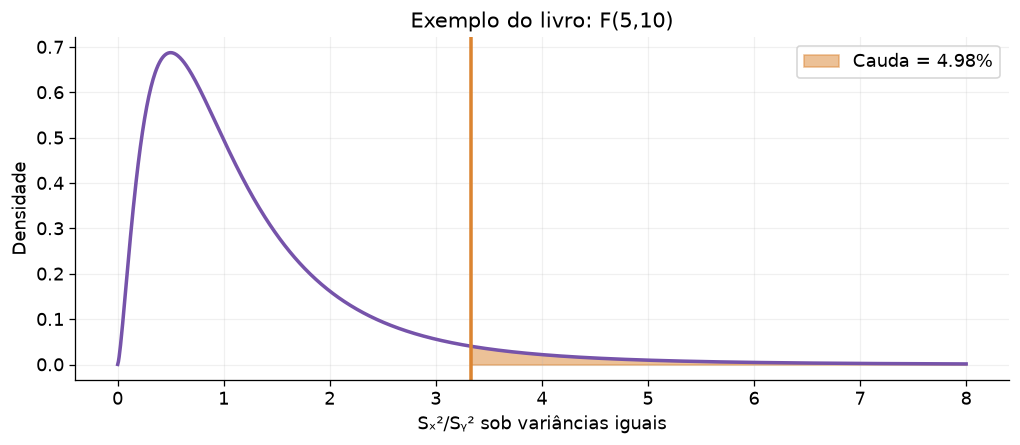

In [15]:
f_obs=16.65/5.
p_f=stats.f.sf(f_obs,5,10)
print(f'Razão observada = {f_obs:.4f}; cauda = {p_f:.6f}')
print(f'Evento invertido: {stats.f.cdf(1/f_obs,10,5):.6f}')
fig,ax=plt.subplots(figsize=(9,4))
xx=np.linspace(.001,8,1200);yy=stats.f.pdf(xx,5,10)
ax.plot(xx,yy,color=CORES['roxo'])
ax.fill_between(xx,yy,where=xx>=f_obs,color=CORES['laranja'],alpha=.5,label=f'Cauda = {p_f:.2%}')
ax.axvline(f_obs,color=CORES['laranja']);ax.set(xlabel='Sₓ²/Sᵧ² sob variâncias iguais',ylabel='Densidade',title='Exemplo do livro: F(5,10)');ax.legend()
figura(fig,'15_exemplo_F_gregory')

### 1.16 O que os cinco teoremas nos entregaram?

| Teorema | Construção | Hipóteses essenciais | Distribuição |
|:--|:--|:--|:--|
| 1 | $\sum_{i=1}^kZ_i^2$ | Normais padrão independentes | $\chi_k^2$ |
| 2 | $Q_1+Q_2$ | Qui-quadrados independentes | $\chi_{k_1+k_2}^2$ |
| 3 | $(n-1)S^2/\sigma^2$ | Amostra IID normal | $\chi_{n-1}^2$; $\bar X\perp S^2$ |
| 4 | $Z/\sqrt{U/\nu}$ | Normal padrão e qui-quadrado independentes | $t_\nu$ |
| 5 | $(U/\nu_1)/(V/\nu_2)$ | Qui-quadrados independentes | $F_{\nu_1,\nu_2}$ |

$S^2$ não enviesado é uma afirmação mais geral do que o teorema 3. E $\chi$, $S$ e $\chi^2$ reduzido são transformações das variáveis acima, com jacobianos próprios. Vamos usar esses resultados para construir intervalos; não precisamos medir muitos $\bar x_r$ para aplicar as fórmulas a **uma** amostra real.

## Parte 2 — Intervalos de confiança
### 2.1 O intervalo é que varia — slides 71–74

Fixemos uma população, com parâmetro $\mu$. Um procedimento recebe os dados $D$ e devolve extremos $L(D)$ e $H(D)$. Um intervalo de confiança de nível $1-\alpha$ satisfaz

$$P_\mu\big[L(D)\leq\mu\leq H(D)\big]=1-\alpha,$$

exatamente ou aproximadamente, conforme o modelo e a construção. A probabilidade se refere à **distribuição de $D$**. Antes de medir, os extremos são aleatórios; depois, $[L(d),H(d)]$ é um intervalo numérico. No tratamento frequentista, $\mu$ é fixo: para esses dados, o intervalo contém ou não contém o parâmetro. O nível caracteriza a regra de construção.

Vamos definir um **quantil** sem atalhos: $q_p$ é um valor cuja CDF vale $p$, isto é, $P(A\leq q_p)=p$ para uma distribuição contínua estritamente crescente. A SciPy fornece esses valores por `ppf(p)`.

Se um pivô $A(D,\mu)$ tem distribuição conhecida e quantis $q_{\alpha/2}$ e $q_{1-\alpha/2}$, então

$$P_\mu(q_{\alpha/2}\leq A(D,\mu)\leq q_{1-\alpha/2})=1-\alpha.$$

A tarefa algébrica é **isolar $\mu$ dentro desse evento**. A tarefa experimental é substituir os dados observados nas expressões finais. Não integramos uma densidade em $\mu$ para obter essa cobertura.

### 2.2 Média com $\sigma$ conhecido

**Hipóteses exatas:** amostra IID normal, $\sigma$ conhecido, tamanho $n$ fixado. O pivô é

$$Z=\frac{\bar X-\mu}{\sigma/\sqrt n}\sim\mathcal N(0,1).$$

Seja $z=z_{1-\alpha/2}>0$. Pela simetria da normal,

$$-z\leq\frac{\bar X-\mu}{\sigma/\sqrt n}\leq z
\iff -z\frac\sigma{\sqrt n}\leq\bar X-\mu\leq z\frac\sigma{\sqrt n}
\iff\bar X-z\frac\sigma{\sqrt n}\leq\mu\leq\bar X+z\frac\sigma{\sqrt n}.$$

O intervalo observado é

$$\boxed{\bar x\pm z_{1-\alpha/2}\frac\sigma{\sqrt n}}.$$

**Exemplo dos slides 71–72:** $n=10$, $\sigma=1$, $\bar x=5.40$. Um desvio padrão da média é $1/\sqrt{10}=0.31623$, produzindo $[5.08377,5.71623]$. A cobertura de $\pm1$ desvio padrão é $2\Phi(1)-1=68.26895\%$, não exatamente 68%. Para exatamente 68%, usamos $z_{0.84}\approx0.99446$. Os $0.32$ dos slides são um arredondamento.

Essa conta usa **uma média observada**, calculada a partir de dez medidas. Não são necessárias dez médias observadas para construir o intervalo.

,Nível,Quantil z,Limite inferior,Limite superior
0,0.68000,0.99446,5.08552,5.71448
1,0.68269,1.00000,5.08377,5.71623
2,0.95000,1.95996,4.78020,6.01980
3,0.99000,2.57583,4.58545,6.21455


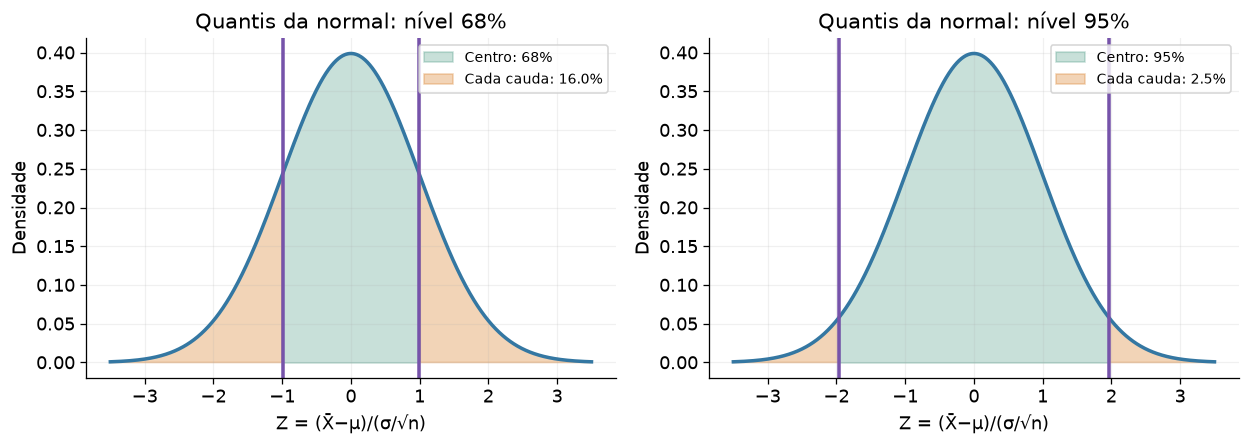

In [16]:
# Quantis, cobertura e intervalo observado dos slides.
linhas=[]
for nivel in [.68,2*stats.norm.cdf(1)-1,.95,.99]:
    zcrit=stats.norm.ppf((1+nivel)/2)
    linhas.append([nivel,zcrit,5.4-zcrit/np.sqrt(10),5.4+zcrit/np.sqrt(10)])
display(pd.DataFrame(linhas,columns=['Nível','Quantil z','Limite inferior','Limite superior']))
fig,ax=plt.subplots(1,2,figsize=(11,4))
g=np.linspace(-3.5,3.5,800);dens=stats.norm.pdf(g)
for axt,nivel in zip(ax,[.68,.95]):
    zcrit=stats.norm.ppf((1+nivel)/2)
    axt.plot(g,dens,color=CORES['azul'])
    axt.fill_between(g,dens,where=np.abs(g)<=zcrit,alpha=.25,color=CORES['verde'],label=f'Centro: {nivel:.0%}')
    axt.fill_between(g,dens,where=np.abs(g)>zcrit,alpha=.35,color=CORES['laranja'],label=f'Cada cauda: {(1-nivel)/2:.1%}')
    for lim in [-zcrit,zcrit]:axt.axvline(lim,color=CORES['roxo'])
    axt.set(xlabel='Z = (X̄−μ)/(σ/√n)',ylabel='Densidade',title=f'Quantis da normal: nível {nivel:.0%}');axt.legend(fontsize=9)
    verificar(f'Área central normal {nivel}',np.isclose(stats.norm.cdf(zcrit)-stats.norm.cdf(-zcrit),nivel))
figura(fig,'16_quantiles_normal_IC')

### 2.3 Reproduzir o experimento do slide 77

O slide mostra **20 amostras, cada uma com dez medidas**, de uma população $\mu=5$, $\sigma=1$. Cada linha horizontal é um intervalo calculado a partir de uma média diferente. A linha vertical em 5 é o parâmetro populacional fixo, conhecido na simulação.

Vamos reproduzir esse desenho experimental com novos dados de semente fixa. A semente e os dados originais do slide não são fornecidos, portanto os nossos centros não precisam ser iguais aos da imagem. Usaremos a regra de um desvio padrão da média, de cobertura $p_\star=0.682689\ldots$.

O slide observou 13 coberturas em 20, isto é, 65%. Isso é compatível com a regra: o número de intervalos que contêm $\mu$, sob experimentos independentes, segue

$$K\sim\operatorname{Binomial}(20,p_\star),\qquad
\mathbb E[K]=20p_\star\approx13.65.$$

A fração $K/20$ não tem obrigação de ser exatamente $p_\star$. Em $R$ repetições, sua escala de flutuação é $\sqrt{p_\star(1-p_\star)/R}$, pois cada indicador de cobertura é uma Bernoulli. O histograma das médias e o gráfico dos intervalos são duas representações do **mesmo conjunto de experimentos completos**.

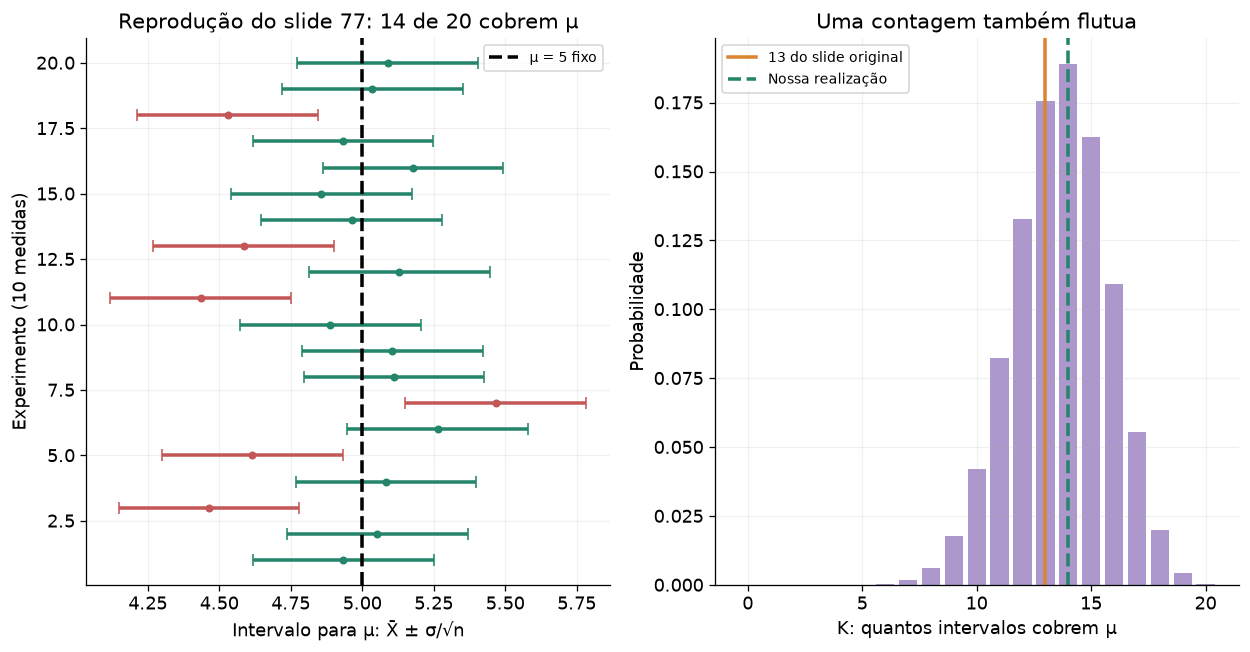

P(K=13) = 0.1757; E[K] = 13.6538
Cobertura em 60000 experimentos já gerados: 68.3883%


In [17]:
# Reprodução independente do slide: a semente foi fixada antes de observar a cobertura.
rng_slide=np.random.default_rng(77)
dados_slide=rng_slide.normal(5,1,size=(20,10))
medias_slide=dados_slide.mean(axis=1)
semilargura=1/np.sqrt(10)
cobre_slide=np.abs(medias_slide-5)<=semilargura
fig,ax=plt.subplots(1,2,figsize=(11,5.8))
for j,(m,cobre) in enumerate(zip(medias_slide,cobre_slide)):
    cor=CORES['verde'] if cobre else CORES['vermelho']
    ax[0].errorbar(m,j+1,xerr=semilargura,fmt='o',color=cor,capsize=4,ms=4)
ax[0].axvline(5,color='black',ls='--',label='μ = 5 fixo')
ax[0].set(xlabel='Intervalo para μ: X̄ ± σ/√n',ylabel='Experimento (10 medidas)',
          title=f'Reprodução do slide 77: {cobre_slide.sum()} de 20 cobrem μ')
ax[0].legend(fontsize=9)
p_estrela=2*stats.norm.cdf(1)-1
kgrid=np.arange(21)
ax[1].bar(kgrid,stats.binom.pmf(kgrid,20,p_estrela),color=CORES['roxo'],alpha=.6)
ax[1].axvline(13,color=CORES['laranja'],label='13 do slide original')
ax[1].axvline(cobre_slide.sum(),color=CORES['verde'],ls='--',label='Nossa realização')
ax[1].set(xlabel='K: quantos intervalos cobrem μ',ylabel='Probabilidade',title='Uma contagem também flutua');ax[1].legend(fontsize=9)
figura(fig,'17_reproducao_slide_77')
print(f'P(K=13) = {stats.binom.pmf(13,20,p_estrela):.4f}; E[K] = {20*p_estrela:.4f}')
print(f'Cobertura em {R} experimentos já gerados: {np.mean(np.abs(medias-mu)<=sigma/np.sqrt(n)):.4%}')
verificar('Cobertura de um erro padrão conhecido',
          abs(np.mean(np.abs(medias-mu)<=sigma/np.sqrt(n))-p_estrela)<5*np.sqrt(p_estrela*(1-p_estrela)/R))

### 2.4 Por que devemos ter cuidado com $p(\mu)$?

A densidade amostral normal é

$$f_{\bar X}(\bar x\mid\mu,\sigma)
=\frac1{\sqrt{2\pi\sigma^2/n}}
 e^{-(\bar x-\mu)^2/(2\sigma^2/n)}.$$

Ela é normalizada na **variável que será medida**, $\bar x$, para cada $\mu$ fixo. Depois de observar $\bar x$, a mesma expressão, estudada como função de $\mu$, é uma likelihood. Não mudamos o condicionamento apenas por mudar o eixo do gráfico.

Para obter uma posterior precisamos especificar a prior:

$$p(\mu\mid D,\sigma)=\frac{L(\mu;D,\sigma)\pi(\mu)}{\int L(m;D,\sigma)\pi(m)\,dm}.$$

No modelo IID normal com $\sigma$ conhecido, o fator da likelihood que depende de $\mu$ é $e^{-n(\mu-\bar x)^2/(2\sigma^2)}$. Isso segue da identidade da soma de quadrados; os resíduos em torno de $\bar x$ são constantes em $\mu$.

Com prior normal $\mu\sim\mathcal N(m_0,\tau_0^2)$, completando o quadrado,

$$-2\log[L(\mu)\pi(\mu)]=\frac n{\sigma^2}(\mu-\bar x)^2+\frac1{\tau_0^2}(\mu-m_0)^2+\text{constante}
=P\mu^2-2B_0\mu+\text{constante},$$

com $P=n/\sigma^2+1/\tau_0^2$ e $B_0=n\bar x/\sigma^2+m_0/\tau_0^2$. Reescrevendo $P\mu^2-2B_0\mu=P(\mu-B_0/P)^2-B_0^2/P$, obtemos

$$\tau_D^{-2}=\frac n{\sigma^2}+\frac1{\tau_0^2},\qquad
m_D=\tau_D^2\left(\frac{n\bar x}{\sigma^2}+\frac{m_0}{\tau_0^2}\right),$$
$$p(\mu\mid D,\sigma)=\mathcal N(m_D,\tau_D^2).$$

No limite de prior plana em toda a reta, a posterior normalizada é $\mathcal N(\bar x,\sigma^2/n)$ e seus intervalos centrais coincidem numericamente com os intervalos de confiança anteriores. A prior plana nesse limite é imprópria, mas a posterior é própria para $n\geq1$. A coincidência numérica não iguala as interpretações: a posterior permite uma probabilidade sobre $\mu$ **condicionada aos dados**.

Na pesquisa, uma curva sobre $H_0$ ou sobre a amplitude de uma correlação precisa indicar se é likelihood, posterior ou distribuição de um estimador entre catálogos simulados. A semelhança do desenho não identifica qual dessas perguntas foi respondida.

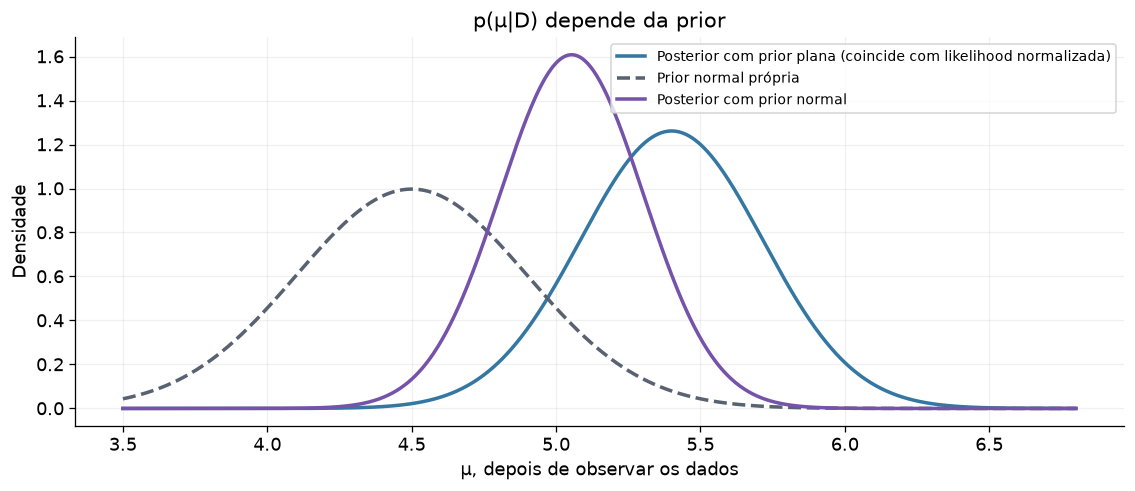

,Construção,Centro,Inferior,Superior
0,IC normal 95%,5.40000,4.78020,6.01980
1,"Credibilidade 95%, prior normal",5.05385,4.56764,5.54005


In [18]:
# Mesmos dados; prior diferente produz uma posterior diferente.
xb,sig_obs,n_obs=5.4,1.,10
m0,tau0=4.5,.4
tauD=1/np.sqrt(n_obs/sig_obs**2+1/tau0**2)
mD=tauD**2*(n_obs*xb/sig_obs**2+m0/tau0**2)
mg=np.linspace(3.5,6.8,900)
fig,ax=plt.subplots(figsize=(10,4.4))
ax.plot(mg,stats.norm.pdf(mg,xb,sig_obs/np.sqrt(n_obs)),color=CORES['azul'],label='Posterior com prior plana (coincide com likelihood normalizada)')
ax.plot(mg,stats.norm.pdf(mg,m0,tau0),'--',color=CORES['cinza'],label='Prior normal própria')
ax.plot(mg,stats.norm.pdf(mg,mD,tauD),color=CORES['roxo'],label='Posterior com prior normal')
ax.set(xlabel='μ, depois de observar os dados',ylabel='Densidade',title='p(μ|D) depende da prior');ax.legend(fontsize=9)
figura(fig,'18_likelihood_posterior_mu')
display(pd.DataFrame({'Construção':['IC normal 95%','Credibilidade 95%, prior normal'],
                     'Centro':[xb,mD],
                     'Inferior':[xb-stats.norm.ppf(.975)/np.sqrt(10),mD-stats.norm.ppf(.975)*tauD],
                     'Superior':[xb+stats.norm.ppf(.975)/np.sqrt(10),mD+stats.norm.ppf(.975)*tauD]}))

### 2.5 Caudas iguais e maior densidade — slides 75–76

O nível sozinho não escolhe um único intervalo. Para uma densidade contínua, o intervalo de **caudas iguais** (ETI) deixa $\alpha/2$ em cada cauda. Um conjunto de **maior densidade** (HDI/HDR) seleciona os valores com densidade acima de um limiar, até somar a probabilidade desejada. Para densidades unimodais regulares, esse conjunto é um intervalo e costuma ser o mais curto naquela parametrização.

A distinção aplica-se à escolha da região de um **pivô**, antes da inversão para um IC, ou à escolha de uma região de uma **posterior**, para credibilidade. É necessário dizer a que distribuição a área pertence. Um intervalo curto no pivô não é necessariamente o mais curto no parâmetro após uma inversão não linear.

Para uma normal ou uma Student centrada, simétrica e unimodal, ETI e HDI coincidem. A frase do slide de que “só concordam se a distribuição é simétrica” deve ser lida como uma orientação para exemplos usuais, não como um teorema universal: simetria multimodal pode produzir uma região de maior densidade **desconexa**, e coincidências em um nível particular não exigem simetria.

Vamos ilustrar com uma distribuição Gamma de um parâmetro positivo $A$, **assumida aqui como posterior didática**, $A\mid D\sim\operatorname{Gamma}(3,1)$. Sua densidade já foi definida, e $A$ é adimensional neste exemplo. Não estamos afirmando que essa é a posterior da variância dos exemplos normais.

Para a Gamma unimodal com extremos interiores, um intervalo mínimo $[l,h]$ satisfaz $F(h)-F(l)=1-\alpha$ e $f(l)=f(h)$. Podemos calcular $l=F^{-1}(p)$, $h=F^{-1}(p+1-\alpha)$ e minimizar a largura para $0\leq p\leq\alpha$.

De fato, derivar $F(F^{-1}(p))=p$ dá $(F^{-1})'(p)=1/f(F^{-1}(p))$. A derivada da largura é $1/f(h)-1/f(l)$; num mínimo interior ela se anula, portanto as densidades dos extremos são iguais.


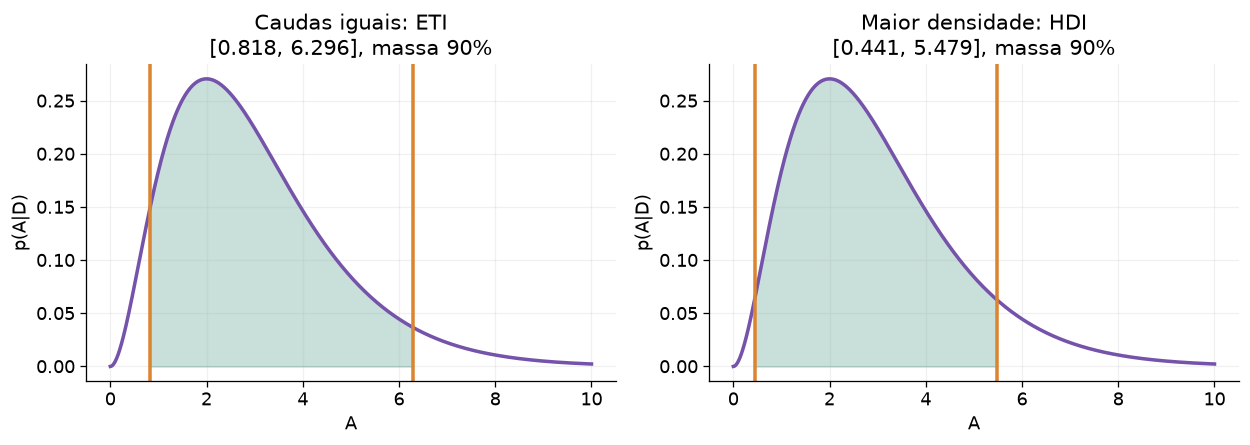

In [19]:
# ETI e HDI: a área pertence a uma posterior Gamma declarada.
distA=stats.gamma(3,scale=1)
nivelA=.9
alphaA=1-nivelA
eti=distA.ppf([alphaA/2,1-alphaA/2])
resultado=optimize.minimize_scalar(lambda p:distA.ppf(p+nivelA)-distA.ppf(p),
                                  bounds=(1e-8,alphaA-1e-8),method='bounded',options={'xatol':1e-12})
hdi=distA.ppf([resultado.x,resultado.x+nivelA])
fig,ax=plt.subplots(1,2,figsize=(11,4))
aa=np.linspace(.001,10,1000);yy=distA.pdf(aa)
for axt,intervalo,nome in zip(ax,[eti,hdi],['Caudas iguais: ETI','Maior densidade: HDI']):
    lo,hi=intervalo
    axt.plot(aa,yy,color=CORES['roxo'])
    axt.fill_between(aa,yy,where=(aa>=lo)&(aa<=hi),color=CORES['verde'],alpha=.25)
    axt.axvline(lo,color=CORES['laranja']);axt.axvline(hi,color=CORES['laranja'])
    axt.set(xlabel='A',ylabel='p(A|D)',title=f'{nome}\n[{lo:.3f}, {hi:.3f}], massa 90%')
figura(fig,'19_ETI_HDI')
verificar('ETI: massa correta',np.isclose(distA.cdf(eti[1])-distA.cdf(eti[0]),nivelA))
verificar('HDI: massa correta',np.isclose(distA.cdf(hdi[1])-distA.cdf(hdi[0]),nivelA))
verificar('HDI: densidades dos extremos iguais',np.isclose(distA.pdf(hdi[0]),distA.pdf(hdi[1]),rtol=1e-5))
verificar('HDI mais curto neste exemplo',np.diff(hdi)[0]<np.diff(eti)[0])

### 2.6 O exemplo da pesquisa eleitoral — slide 73

Sob uma amostra simples de $n=800$ respostas independentes, com fração observada $\hat p=0.53$, a aproximação normal para a binomial dá o intervalo de Wald:

$$\hat p\pm z_{0.975}\sqrt{\frac{\hat p(1-\hat p)}{n}}
\approx 0.53\pm0.0346.$$

Assim obtemos aproximadamente $[49.54\%,56.46\%]$. A proporção populacional $p$ é fixa; $\hat p$ varia entre pesquisas. Esse intervalo é **aproximado**, não exato, e pode ter cobertura ruim perto de 0 e 1 ou em amostras pequenas. A hipótese de amostragem simples também não representa automaticamente uma pesquisa real com desenho complexo.

“95% de confiança” não significa que 95% das pesquisas futuras estarão a até 3.5 pontos da **primeira pesquisa**. A diferença entre duas proporções independentes tem aproximadamente variância $2p(1-p)/n$, não $p(1-p)/n$. A primeira também flutua. O slide mistura essas duas interpretações.

Intervalo de Wald: [49.541%, 56.459%]
Margem: 3.459 pontos percentuais
Na aproximação, P(|p̂₁−p̂₂|≤1.96 SE) ≈ 83.422%


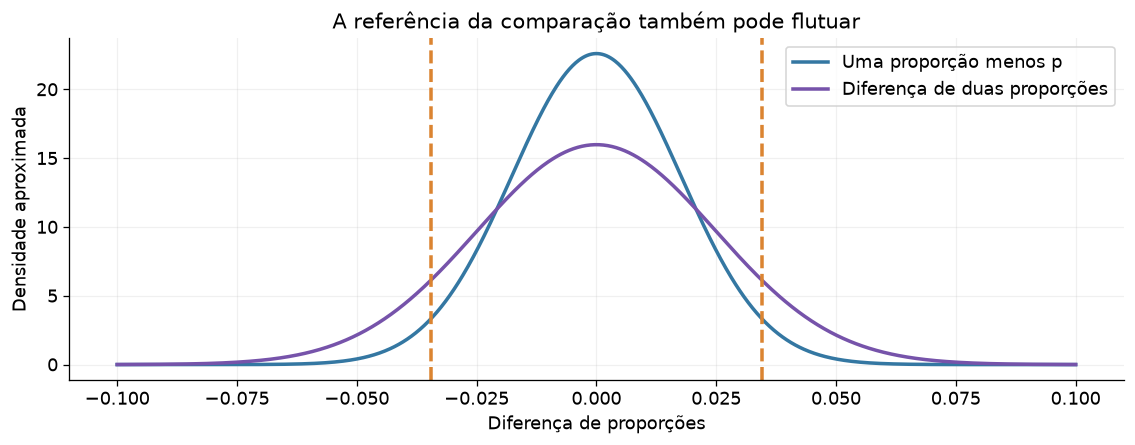

In [20]:
# Reprodução numérica da margem eleitoral e da distinção entre duas pesquisas.
p_ele,n_ele=.53,800
z95=stats.norm.ppf(.975)
se_ele=np.sqrt(p_ele*(1-p_ele)/n_ele)
print(f'Intervalo de Wald: [{100*(p_ele-z95*se_ele):.3f}%, {100*(p_ele+z95*se_ele):.3f}%]')
print(f'Margem: {100*z95*se_ele:.3f} pontos percentuais')
print(f'Na aproximação, P(|p̂₁−p̂₂|≤1.96 SE) ≈ {2*stats.norm.cdf(z95/np.sqrt(2))-1:.3%}')
fig,ax=plt.subplots(figsize=(10,4))
xx=np.linspace(-.10,.10,900)
ax.plot(xx,stats.norm.pdf(xx,0,se_ele),label='Uma proporção menos p',color=CORES['azul'])
ax.plot(xx,stats.norm.pdf(xx,0,np.sqrt(2)*se_ele),label='Diferença de duas proporções',color=CORES['roxo'])
for lim in [-z95*se_ele,z95*se_ele]:ax.axvline(lim,color=CORES['laranja'],ls='--')
ax.set(xlabel='Diferença de proporções',ylabel='Densidade aproximada',title='A referência da comparação também pode flutuar');ax.legend()
figura(fig,'20_exemplo_eleitoral')

### 2.7 Média com $\sigma$ desconhecido — slides 78–80

Não conhecer $\sigma$ não altera a população normal assumida. Continuamos tendo $\bar X\sim\mathcal N(\mu,\sigma^2/n)$, mas não podemos calcular a escala do intervalo anterior. Estimamos a escala por $S$ e usamos a distribuição **da razão inteira**:

$$T=\frac{\bar X-\mu}{S/\sqrt n}\sim t_\nu,\qquad \nu=n-1.$$

Se $t_c=t_{1-\alpha/2,\nu}$, o evento central é

$$-t_c\leq\frac{\bar X-\mu}{S/\sqrt n}\leq t_c.$$

Como $S>0$ quase certamente sob uma amostra normal não degenerada, multiplicamos sem mudar o sinal e isolamos $\mu$:

$$\boxed{\bar X-t_c\frac S{\sqrt n}\leq\mu\leq\bar X+t_c\frac S{\sqrt n}}.$$

Antes da observação, **$\bar X$ e $S$ são aleatórios**. Depois, substituímos por $\bar x$ e $s$. O uso de $s$ dentro de uma expressão que ainda trata a amostra como aleatória, no slide 78, esconde essa distinção; aqui manteremos as maiúsculas até a última etapa.

Para $n=10$ e 95%, $\nu=9$, $t_c\approx2.262$, enquanto $z_c\approx1.960$. Usar $\bar x\pm1.960s/\sqrt n$ ignora a variabilidade adicional da estimativa de escala e tem cobertura menor que 95%.

O intervalo Student costuma ser mais largo do que o intervalo normal **para a mesma escala numérica** $s=\sigma$. Entre amostras, $s$ varia; não é verdade que cada intervalo Student será obrigatoriamente mais largo que um intervalo com a verdadeira $\sigma$. A correção é sobre a cobertura do procedimento.

Os slides 79–80 desenham densidades dos pivôs $Z$ e $T$. Vamos reproduzir as caudas e os quantis, e depois comparar os intervalos calculados dos mesmos dados. A Student simétrica permite a mesma inversão que a normal; a diferença está na distribuição usada para escolher o quantil.

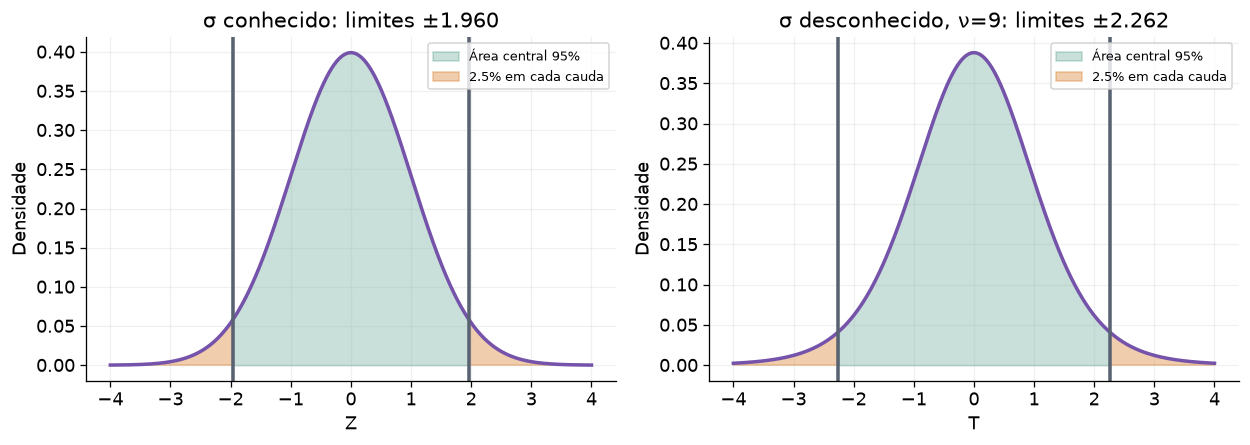

Um experimento de 10 medidas: x̄=4.93304, s=1.33721
IC normal (σ realmente conhecido): [4.31324418 5.55283424]
IC Student (σ estimado): [3.9764547  5.88962371]


In [21]:
# Reproduzir os diagramas dos slides 79–80: densidades dos pivôs, não de μ.
nivel=.95
zc=stats.norm.ppf((1+nivel)/2)
tc=stats.t.ppf((1+nivel)/2,9)
fig,ax=plt.subplots(1,2,figsize=(11,4))
g=np.linspace(-4,4,1000)
for axt,dist,crit,titulo,rotulo in [(ax[0],stats.norm(),zc,'σ conhecido','Z'),
                                  (ax[1],stats.t(9),tc,'σ desconhecido, ν=9','T')]:
    dens=dist.pdf(g)
    axt.plot(g,dens,color=CORES['roxo'])
    axt.fill_between(g,dens,where=np.abs(g)<=crit,color=CORES['verde'],alpha=.25,label='Área central 95%')
    axt.fill_between(g,dens,where=np.abs(g)>crit,color=CORES['laranja'],alpha=.4,label='2.5% em cada cauda')
    for lim in [-crit,crit]:axt.axvline(lim,color=CORES['cinza'])
    axt.set(xlabel=rotulo,ylabel='Densidade',title=f'{titulo}: limites ±{crit:.3f}');axt.legend(fontsize=8)
figura(fig,'21_slides_79_80_pivos')
print(f'Um experimento de 10 medidas: x̄={medias_slide[0]:.5f}, s={dados_slide[0].std(ddof=1):.5f}')
s_primeiro=dados_slide[0].std(ddof=1)
print('IC normal (σ realmente conhecido):',medias_slide[0]+np.array([-1,1])*zc/np.sqrt(10))
print('IC Student (σ estimado):',medias_slide[0]+np.array([-1,1])*tc*s_primeiro/np.sqrt(10))
verificar('Área central Student 95%',np.isclose(stats.t.cdf(tc,9)-stats.t.cdf(-tc,9),.95))

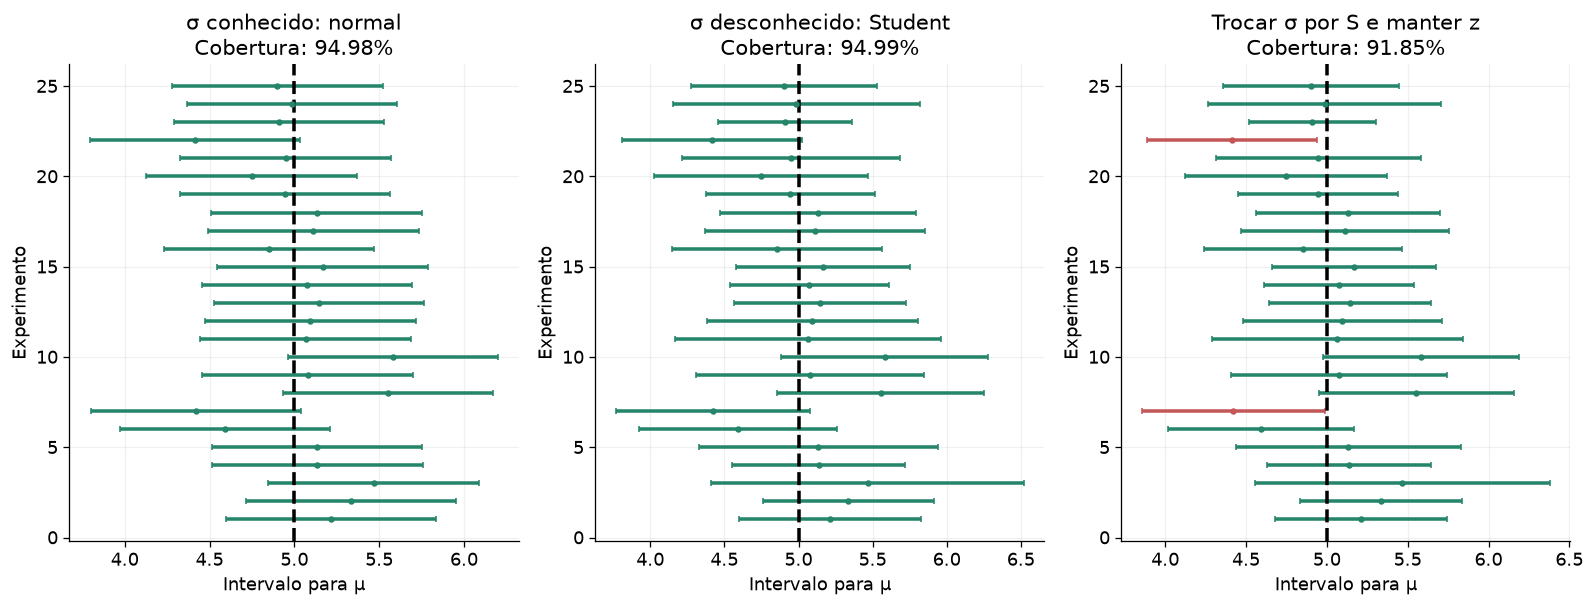

,Procedimento,Cobertura,Largura média
0,σ conhecido: normal,0.94983,1.23959
1,σ desconhecido: Student,0.94987,1.39220
2,Trocar σ por S e manter z,0.91847,1.20623


Cobertura exata de ±z S/√n: 91.83509%


In [22]:
# Os centros e larguras variam. Cobertura: usar muitas amostras completas.
s_amostral=np.sqrt(variancias)
regras={'σ conhecido: normal':zc*sigma/np.sqrt(n)*np.ones(R),
        'σ desconhecido: Student':tc*s_amostral/np.sqrt(n),
        'Trocar σ por S e manter z':zc*s_amostral/np.sqrt(n)}
fig,ax=plt.subplots(1,3,figsize=(14,5.4))
resumo=[]
for axt,(nome,largs) in zip(ax,regras.items()):
    cobrem=np.abs(medias-mu)<=largs
    for j in range(25):
        cor=CORES['verde'] if cobrem[j] else CORES['vermelho']
        axt.errorbar(medias[j],j+1,xerr=largs[j],fmt='o',ms=3,capsize=2,color=cor)
    axt.axvline(mu,color='black',ls='--')
    axt.set(xlabel='Intervalo para μ',ylabel='Experimento',title=f'{nome}\nCobertura: {cobrem.mean():.2%}')
    resumo.append([nome,cobrem.mean(),(2*largs).mean()])
figura(fig,'22_cobertura_normal_student')
display(pd.DataFrame(resumo,columns=['Procedimento','Cobertura','Largura média']))
# A cobertura da regra ingênua é calculável exatamente pela Student.
cobertura_ingenua=2*stats.t.cdf(zc,n-1)-1
print(f'Cobertura exata de ±z S/√n: {cobertura_ingenua:.5%}')
for nome in ['σ conhecido: normal','σ desconhecido: Student']:
    verificar(f'Cobertura 95% {nome}',abs(np.mean(np.abs(medias-mu)<=regras[nome])-.95)<5*np.sqrt(.95*.05/R))
verificar('Cobertura da regra ingênua',abs(np.mean(np.abs(medias-mu)<=regras['Trocar σ por S e manter z'])-cobertura_ingenua)<.006)

### 2.8 Um intervalo para a média não prevê uma nova medida

No modelo normal, $S$ descreve a dispersão **individual**; $S/\sqrt n$ estima a dispersão **da média**. Mesmo quando a média é determinada com precisão, uma nova medida continua dispersa.

Se $X_{\rm novo}$ é uma nova observação independente da amostra, então $X_{\rm novo}-\bar X$ é normal com média zero e variância $\sigma^2(1+1/n)$. Também é independente de $S^2$ pela construção gaussiana. Assim,

$$\frac{X_{\rm novo}-\bar X}{S\sqrt{1+1/n}}\sim t_{n-1}.$$

O **intervalo de previsão** frequentista para uma nova medida é

$$\bar x\pm t_{1-\alpha/2,n-1}s\sqrt{1+1/n}.$$

É mais largo que o intervalo para $\mu$ porque inclui a dispersão da nova observação. A cobertura de previsão é sobre a repetição conjunta da amostra e da nova observação. Se conhecermos $\sigma$, trocamos o quantil Student por normal e $s$ por $\sigma$.

Por exemplo, estimar a média de uma população de fontes não localiza uma nova fonte com a mesma precisão. Essa separação entre dispersão populacional e precisão de uma estimativa aparecerá novamente em modelos hierárquicos.

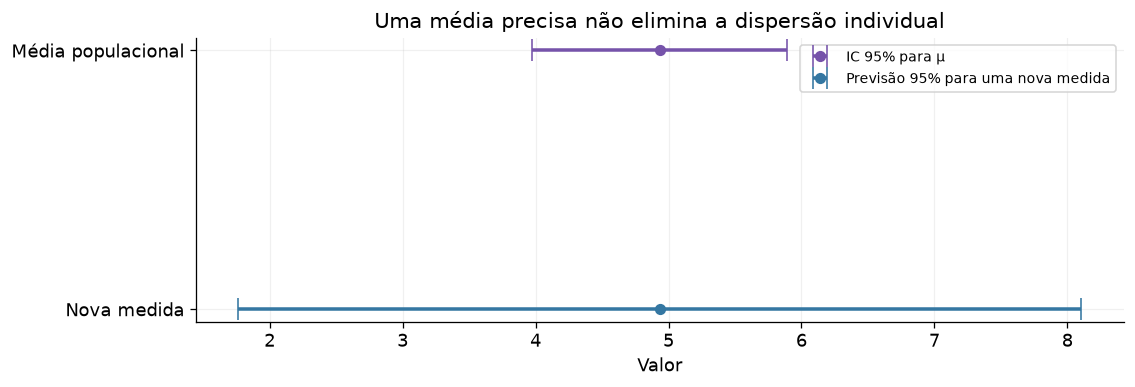

Cobertura simulada de previsão: 94.962%


In [23]:
# Comparar os dois intervalos para os mesmos dados do exemplo de uma amostra.
m_ex=medias_slide[0];s_ex=dados_slide[0].std(ddof=1);n_ex=10
h_media=tc*s_ex/np.sqrt(n_ex)
h_previsao=tc*s_ex*np.sqrt(1+1/n_ex)
fig,ax=plt.subplots(figsize=(10,3.5))
ax.errorbar(m_ex,1,xerr=h_media,fmt='o',capsize=7,color=CORES['roxo'],label='IC 95% para μ')
ax.errorbar(m_ex,0,xerr=h_previsao,fmt='o',capsize=7,color=CORES['azul'],label='Previsão 95% para uma nova medida')
ax.set(yticks=[0,1],yticklabels=['Nova medida','Média populacional'],xlabel='Valor',title='Uma média precisa não elimina a dispersão individual');ax.legend(fontsize=9)
figura(fig,'23_media_e_previsao')
novas=rng.normal(mu,sigma,size=R)
cob_pred=np.mean(np.abs(novas-medias)<=tc*s_amostral*np.sqrt(1+1/n))
print(f'Cobertura simulada de previsão: {cob_pred:.3%}')
verificar('Intervalo de previsão: cobertura 95%',abs(cob_pred-.95)<5*np.sqrt(.95*.05/R))

### 2.9 Diferença de duas médias: variâncias conhecidas — slide 81

Considere duas amostras independentes:

$$X_i\sim\mathcal N(\mu_x,\sigma_x^2),\quad i=1,\ldots,n_x,
\qquad Y_j\sim\mathcal N(\mu_y,\sigma_y^2),\quad j=1,\ldots,n_y.$$

O parâmetro é $\Delta=\mu_x-\mu_y$ e o estimador $D=\bar X-\bar Y$. Pela independência,

$$\mathbb E[D]=\Delta,\qquad
\operatorname{Var}(D)=\frac{\sigma_x^2}{n_x}+\frac{\sigma_y^2}{n_y}=\mathrm{SE}_D^2.$$

O sinal de subtração nas médias vira **soma** na variância porque o quadrado do coeficiente $-1$ é $+1$. As amostras gaussianas tornam $D$ exatamente normal. Portanto,

$$Z_D=\frac{D-\Delta}{\mathrm{SE}_D}\sim\mathcal N(0,1),\qquad
\boxed{\Delta\in\bar x-\bar y\pm z_{1-\alpha/2}\mathrm{SE}_D}.$$

Não precisamos realizar muitas determinações de $\bar x$ e $\bar y$ para usar a fórmula: **uma amostra de cada população** fornece um intervalo. As repetições simuladas mostram a cobertura da regra.

Usaremos como exemplo duas configurações de um instrumento medindo a mesma amplitude em unidades arbitrárias, com possível deslocamento médio. “Controle” e “ensaio” são nomes das populações; a diferença é o parâmetro que queremos estimar.

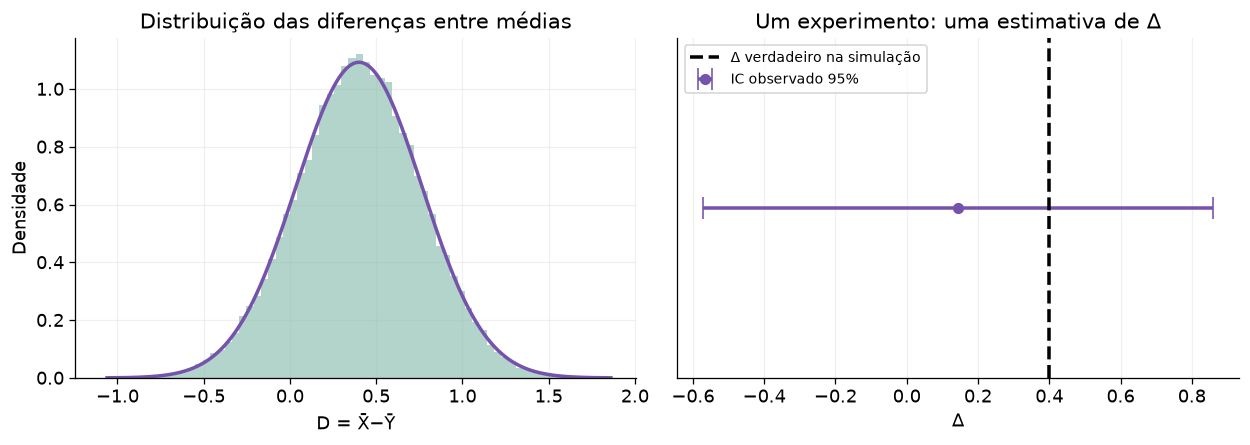

IC observado: -0.57189 a 0.85947; cobertura = 95.088%


In [24]:
# Duas populações com variâncias conhecidas e diferentes.
nx,ny=12,18
mux,muy,sigx,sigy=2.0,1.6,.8,1.2
delta=mux-muy
x2=rng.normal(mux,sigx,size=(R,nx))
y2=rng.normal(muy,sigy,size=(R,ny))
d2=x2.mean(axis=1)-y2.mean(axis=1)
seD=np.sqrt(sigx**2/nx+sigy**2/ny)
cob2=np.mean(np.abs(d2-delta)<=zc*seD)
fig,ax=plt.subplots(1,2,figsize=(11,4))
g=np.linspace(delta-4*seD,delta+4*seD,900)
ax[0].hist(d2,bins=70,density=True,alpha=.35,color=CORES['verde'])
ax[0].plot(g,stats.norm.pdf(g,delta,seD),color=CORES['roxo'])
ax[0].set(xlabel='D = X̄−Ȳ',ylabel='Densidade',title='Distribuição das diferenças entre médias')
ax[1].errorbar(d2[0],0,xerr=zc*seD,fmt='o',capsize=7,color=CORES['roxo'],label='IC observado 95%')
ax[1].axvline(delta,color='black',ls='--',label='Δ verdadeiro na simulação')
ax[1].set(xlabel='Δ',yticks=[],title='Um experimento: uma estimativa de Δ');ax[1].legend(fontsize=9)
figura(fig,'24_duas_medias_variancias_conhecidas')
print(f'IC observado: {d2[0]-zc*seD:.5f} a {d2[0]+zc*seD:.5f}; cobertura = {cob2:.3%}')
verificar('Diferença de médias: variância conhecida',abs(d2.var()-seD**2)<.005)
verificar('Diferença de médias: cobertura',abs(cob2-.95)<5*np.sqrt(.95*.05/R))

### 2.10 Variâncias desconhecidas, mas iguais — slide 82

Agora supomos uma **variância comum** $\sigma^2$ desconhecida. Não estamos estimando duas variâncias populacionais diferentes; estamos combinando duas estimativas da mesma quantidade. Os tamanhos podem ser diferentes.

Pelo teorema 3,

$$U_x=\frac{(n_x-1)S_x^2}{\sigma^2}\sim\chi_{n_x-1}^2,
\qquad U_y=\frac{(n_y-1)S_y^2}{\sigma^2}\sim\chi_{n_y-1}^2.$$

As amostras independentes permitem usar o teorema 2: $U_x+U_y\sim\chi_\nu^2$, com $\nu=n_x+n_y-2$. Definimos a **variância combinada** ou pooled variance:

$$S_p^2=\frac{(n_x-1)S_x^2+(n_y-1)S_y^2}{n_x+n_y-2}.$$

A ponderação vem dos quadrados residuais e seus graus de liberdade, não de uma média aritmética arbitrária de variâncias. Temos $\nu S_p^2/\sigma^2\sim\chi_\nu^2$. Além disso, $D$ é independente de $S_p^2$, porque cada média é independente da sua variância e as amostras são independentes. Pelo teorema 4,

$$T_p=\frac{D-\Delta}{S_p\sqrt{1/n_x+1/n_y}}\sim t_\nu.$$

Invertendo o evento central,

$$\boxed{\Delta\in\bar x-\bar y\pm t_{1-\alpha/2,\nu}s_p\sqrt{\frac1{n_x}+\frac1{n_y}}}.$$

Os dois graus de liberdade perdidos correspondem às duas médias ajustadas. Não subtraímos um terceiro grau de liberdade porque estimamos a escala: essa estimação aparece na distribuição Student. A regra “dados menos parâmetros” precisa estar ligada à construção, não aplicada como uma contagem universal.

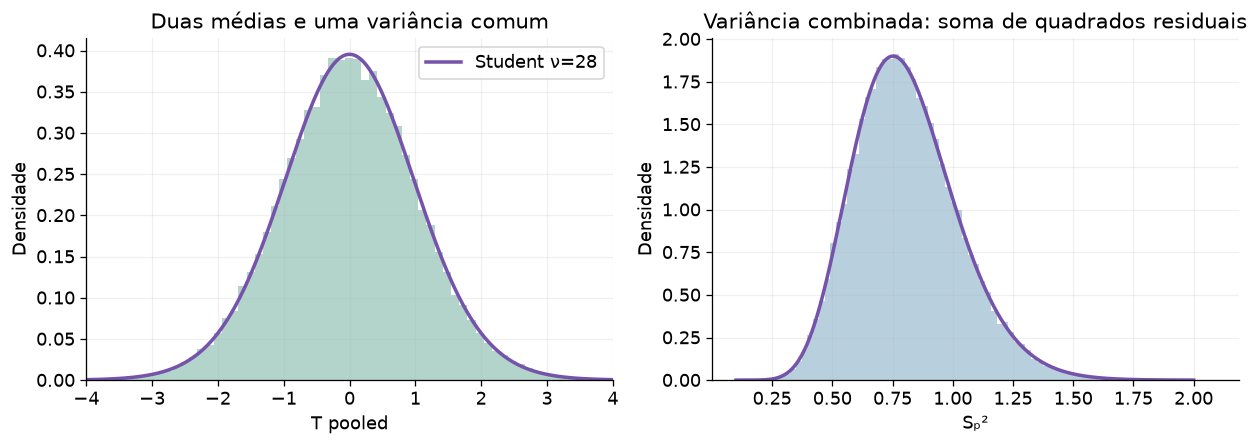

IC observado: [-0.05691, 1.35993]; ν=28
Cobertura simulada: 94.948%


In [25]:
# Mesmo σ nas duas populações: o intervalo pooled é exato sob normalidade.
sig_comum=.9
xp=rng.normal(mux,sig_comum,size=(R,nx))
yp=rng.normal(muy,sig_comum,size=(R,ny))
dp=xp.mean(axis=1)-yp.mean(axis=1)
sp2=((nx-1)*xp.var(axis=1,ddof=1)+(ny-1)*yp.var(axis=1,ddof=1))/(nx+ny-2)
sep=np.sqrt(sp2*(1/nx+1/ny))
nu_p=nx+ny-2
tp=(dp-delta)/sep
tcritp=stats.t.ppf(.975,nu_p)
fig,ax=plt.subplots(1,2,figsize=(11,4))
g=np.linspace(-4,4,900)
ax[0].hist(tp,bins=80,density=True,alpha=.35,color=CORES['verde'])
ax[0].plot(g,stats.t.pdf(g,nu_p),color=CORES['roxo'],label=f'Student ν={nu_p}')
ax[0].set(xlim=(-4,4),xlabel='T pooled',ylabel='Densidade',title='Duas médias e uma variância comum');ax[0].legend()
ax[1].hist(sp2,bins=80,density=True,alpha=.35,color=CORES['azul'])
v=np.linspace(.1,2,900)
ax[1].plot(v,nu_p/sig_comum**2*stats.chi2.pdf(nu_p*v/sig_comum**2,nu_p),color=CORES['roxo'])
ax[1].set(xlabel='Sₚ²',ylabel='Densidade',title='Variância combinada: soma de quadrados residuais')
figura(fig,'25_duas_medias_pooled')
cobp=np.mean(np.abs(dp-delta)<=tcritp*sep)
print(f'IC observado: [{dp[0]-tcritp*sep[0]:.5f}, {dp[0]+tcritp*sep[0]:.5f}]; ν={nu_p}')
print(f'Cobertura simulada: {cobp:.3%}')
verificar('Pooled: cobertura 95%',abs(cobp-.95)<5*np.sqrt(.95*.05/R))
verificar('Pooled: variância não enviesada',abs(sp2.mean()-sig_comum**2)<.01)

### 2.11 Variâncias desconhecidas e diferentes: Welch — slide 83

Agora não supomos uma variância comum. Estimamos diretamente a variância de $D$:

$$W=\frac{S_x^2}{n_x}+\frac{S_y^2}{n_y},\qquad
T_W=\frac{D-\Delta}{\sqrt W}.$$

Não podemos aplicar o teorema 2 como no caso pooled: os qui-quadrados entram com **escalas diferentes**. A distribuição de $T_W$ não é exatamente Student, em geral. Welch–Satterthwaite aproxima a distribuição da escala combinada por uma qui-quadrado reescalada, ajustando os dois primeiros momentos.

Vamos mostrar de onde vem o número de graus de liberdade. Seja

$$A=\frac{\sigma_x^2}{n_x},\qquad B=\frac{\sigma_y^2}{n_y},
\qquad m=\mathbb E[W]=A+B.$$

Pela independência das amostras e pela variância gaussiana de $S^2$,

$$\operatorname{Var}(W)=2\left[\frac{A^2}{n_x-1}+\frac{B^2}{n_y-1}\right].$$

Uma variável aproximante $W_\star=m\chi_\nu^2/\nu$ tem média $m$ e variância $2m^2/\nu$. Igualando as variâncias,

$$\nu_\star=\frac{(A+B)^2}{A^2/(n_x-1)+B^2/(n_y-1)}.$$

Como $A,B$ são desconhecidos, fazemos a substituição amostral $a=s_x^2/n_x$, $b=s_y^2/n_y$:

$$\boxed{\hat\nu=\frac{(a+b)^2}{a^2/(n_x-1)+b^2/(n_y-1)}}.$$

**Correção do slide 83:** entre os dois termos do denominador deve aparecer **soma**, não subtração. A variância de uma soma de termos independentes é a soma das variâncias; uma subtração poderia até gerar graus de liberdade negativos. $\hat\nu$ pode ser não inteiro e a Student está bem definida nesse caso. Não precisamos arredondá-lo.

O intervalo é aproximadamente

$$\boxed{\Delta\in\bar x-\bar y\pm t_{1-\alpha/2,\hat\nu}
\sqrt{\frac{s_x^2}{n_x}+\frac{s_y^2}{n_y}}}.$$

Cada amostra fornece sua própria escala e seu próprio $\hat\nu$. A aproximação é especialmente útil quando variâncias e tamanhos são diferentes. Não concluímos “variâncias iguais” porque um teste não encontrou diferença; a suposição de variância comum precisa vir do modelo ou de evidência apropriada.

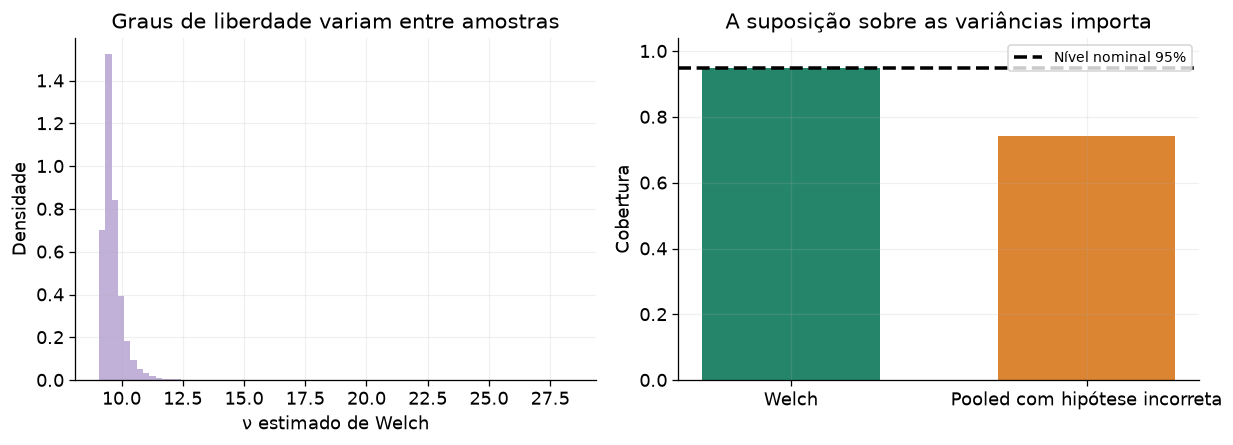

Welch: cobertura ≈ 94.933%; pooled com variâncias desiguais: 74.328%
Uma amostra: ν̂=10.15026, SE=0.65752; IC=[-1.33936, 1.58486]


In [26]:
# Escolher antes da simulação um caso heterogêneo com tamanhos desiguais.
nxw,nyw=10,40
sigxw,sigyw=3.0,1.0
xw=rng.normal(mux,sigxw,size=(R,nxw))
yw=rng.normal(muy,sigyw,size=(R,nyw))
dw=xw.mean(axis=1)-yw.mean(axis=1)
sx2w=xw.var(axis=1,ddof=1);sy2w=yw.var(axis=1,ddof=1)
a=sx2w/nxw;b=sy2w/nyw
sew=np.sqrt(a+b)
nuw=(a+b)**2/(a*a/(nxw-1)+b*b/(nyw-1))
hw=stats.t.ppf(.975,nuw)*sew
# Comparação: impor equivocadamente uma variância comum.
sp2_err=((nxw-1)*sx2w+(nyw-1)*sy2w)/(nxw+nyw-2)
hp_err=stats.t.ppf(.975,nxw+nyw-2)*np.sqrt(sp2_err*(1/nxw+1/nyw))
cobw=np.mean(np.abs(dw-delta)<=hw)
cobp_err=np.mean(np.abs(dw-delta)<=hp_err)
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].hist(nuw,bins=75,density=True,alpha=.45,color=CORES['roxo'])
ax[0].set(xlabel='ν estimado de Welch',ylabel='Densidade',title='Graus de liberdade variam entre amostras')
ax[1].bar(['Welch','Pooled com hipótese incorreta'],[cobw,cobp_err],color=[CORES['verde'],CORES['laranja']],width=.6)
ax[1].axhline(.95,color='black',ls='--',label='Nível nominal 95%')
ax[1].set(ylim=(0,1.04),ylabel='Cobertura',title='A suposição sobre as variâncias importa');ax[1].legend(fontsize=9)
figura(fig,'26_welch_cobertura')
print(f'Welch: cobertura ≈ {cobw:.3%}; pooled com variâncias desiguais: {cobp_err:.3%}')
print(f'Uma amostra: ν̂={nuw[0]:.5f}, SE={sew[0]:.5f}; IC=[{dw[0]-hw[0]:.5f}, {dw[0]+hw[0]:.5f}]')
# Comparação com uma implementação independente da SciPy, para os dados observados.
resultado_scipy=stats.ttest_ind(xw[0],yw[0],equal_var=False).confidence_interval(.95)
verificar('Welch: ν positivo e limitado pelos graus disponíveis',np.all((nuw>=min(nxw-1,nyw-1)-1e-10)&(nuw<=nxw+nyw-2+1e-10)))
verificar('Welch: IC coincide com SciPy',np.allclose([dw[0]-hw[0],dw[0]+hw[0]],[resultado_scipy.low,resultado_scipy.high]))

### 2.12 E se os dados forem pareados ou correlacionados?

As fórmulas anteriores são para **amostras independentes**. Se medimos antes e depois nos mesmos objetos, podemos formar diferenças $D_i=X_i-Y_i$ de cada par e usar uma média e uma variância **das diferenças**. Para pares IID normais,

$$\bar D=\bar X-\bar Y,\qquad
\sigma_D^2=\sigma_x^2+\sigma_y^2-2\operatorname{Cov}(X,Y),$$
$$\frac{\bar D-\Delta}{S_D/\sqrt n}\sim t_{n-1}.$$

Aqui $S_D$ significa o desvio padrão das diferenças pareadas, distinto da escala combinada entre amostras independentes. A covariância pode aumentar ou diminuir a incerteza da diferença.

Na análise GW–galáxias, bins ou estimativas construídas do mesmo céu podem ser correlacionados. A fórmula geral é $\operatorname{Var}(\sum_iw_iX_i)=\sum_{ij}w_iw_jC_{ij}$, com $C_{ij}=\operatorname{Cov}(X_i,X_j)$. Ignorar os termos fora da diagonal pode alterar a escala dos intervalos. No capítulo 6 os exemplos são simples; a lição útil para a pesquisa é verificar a estrutura de independência antes de escolher um pivô.

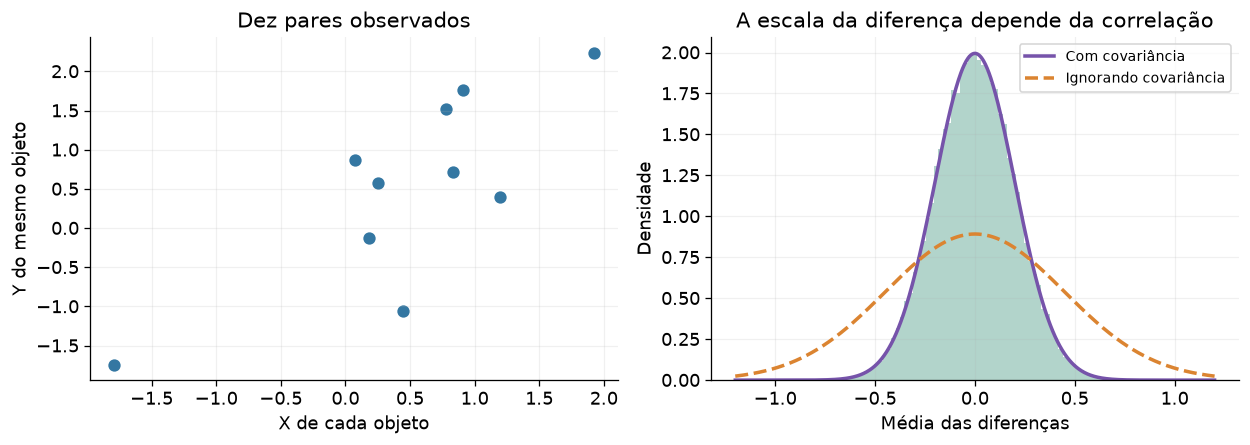

IC pareado: cobertura 94.993%


In [27]:
# Um exemplo pareado: correlação positiva reduz a variância da diferença.
rho=.8
zpar=rng.normal(size=(R,10,2))
xpar=zpar[:,:,0]
ypar=rho*zpar[:,:,0]+np.sqrt(1-rho*rho)*zpar[:,:,1]
dpar=xpar-ypar
mpar=dpar.mean(axis=1);spar=dpar.std(axis=1,ddof=1)
cobpar=np.mean(np.abs(mpar)<=stats.t.ppf(.975,9)*spar/np.sqrt(10))
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].scatter(xpar[0],ypar[0],s=45,color=CORES['azul'])
ax[0].set(xlabel='X de cada objeto',ylabel='Y do mesmo objeto',title='Dez pares observados')
gx=np.linspace(-1.2,1.2,800)
ax[1].hist(mpar,bins=75,density=True,alpha=.35,color=CORES['verde'])
ax[1].plot(gx,stats.norm.pdf(gx,0,np.sqrt((2-2*rho)/10)),color=CORES['roxo'],label='Com covariância')
ax[1].plot(gx,stats.norm.pdf(gx,0,np.sqrt(2/10)),'--',color=CORES['laranja'],label='Ignorando covariância')
ax[1].set(xlabel='Média das diferenças',ylabel='Densidade',title='A escala da diferença depende da correlação');ax[1].legend(fontsize=9)
figura(fig,'27_amostras_pareadas')
print(f'IC pareado: cobertura {cobpar:.3%}')
verificar('Pareamento: variância da diferença média',abs(mpar.var()-(2-2*rho)/10)<.002)

### 2.13 Intervalo para a variância — slide 84

Voltamos a **uma** amostra IID normal, de média desconhecida. Seja $\nu=n-1$. Temos

$$U=\frac{\nu S^2}{\sigma^2}\sim\chi_\nu^2.$$

Defina $q_l=q_{\alpha/2,\nu}$ e $q_h=q_{1-\alpha/2,\nu}$. O evento de probabilidade $1-\alpha$ é

$$q_l\leq\frac{\nu S^2}{\sigma^2}\leq q_h.$$

Como todas as quantidades são positivas, a inversão troca os extremos:

$$\frac1{q_h}\leq\frac{\sigma^2}{\nu S^2}\leq\frac1{q_l}
\iff\boxed{\frac{\nu S^2}{q_h}\leq\sigma^2\leq\frac{\nu S^2}{q_l}}.$$

Depois de observar os dados, usamos $s^2$. O **quantil maior aparece no denominador do limite inferior**. É essa inversão que costuma parecer inesperada na fórmula dos slides.

Como a qui-quadrado é assimétrica, o intervalo não é em geral simétrico em torno de $s^2$. Não devemos substituir por $s^2\pm$ uma margem gaussiana sem justificar a aproximação. Para obter um intervalo para $\sigma$, tomamos a raiz dos dois extremos, uma transformação monótona que preserva o evento de cobertura.

Se a média populacional for conhecida, usamos $S_\mu^2$ e $\nu=n$, conforme a parte 1. A população normal é essencial para a cobertura exata destes intervalos; uma média aproximadamente normal pelo TLC não garante uma variância amostral qui-quadrado.

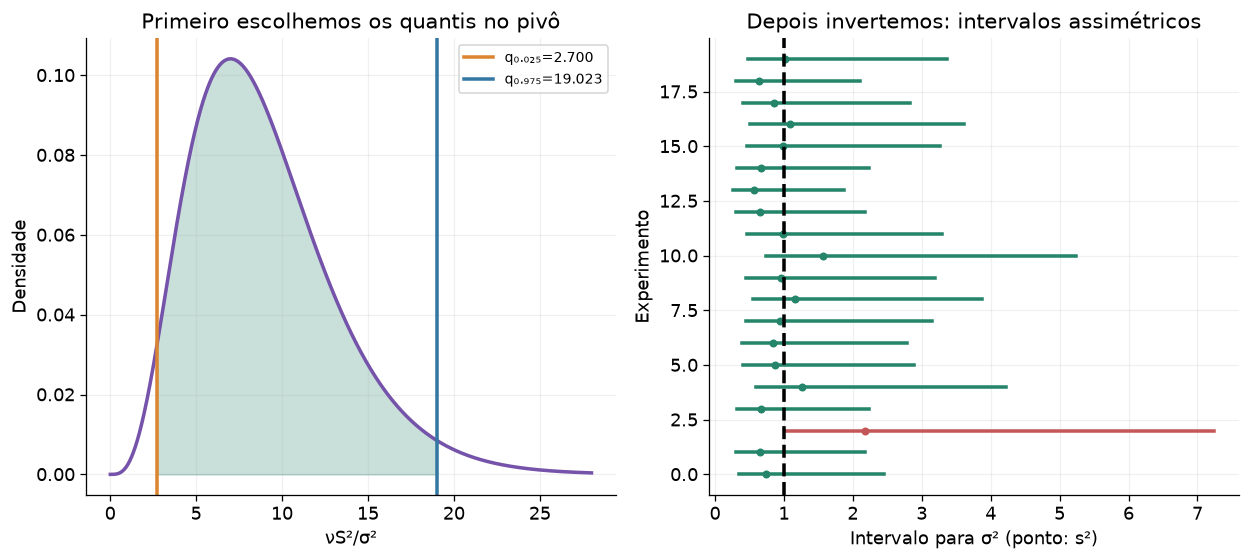

Primeira amostra: s²=0.73746, IC σ²=[0.34890, 2.45783]
IC σ=[0.59068, 1.56775]; cobertura=95.002%


In [28]:
# Um intervalo observado e muitos intervalos para conferir sua cobertura.
nu_var=n-1
ql,qh=stats.chi2.ppf([.025,.975],nu_var)
lo_var=nu_var*variancias/qh
hi_var=nu_var*variancias/ql
cobvar=(lo_var<=sigma**2)&(sigma**2<=hi_var)
fig,ax=plt.subplots(1,2,figsize=(11,5))
xx=np.linspace(.01,28,1000);yy=stats.chi2.pdf(xx,nu_var)
ax[0].plot(xx,yy,color=CORES['roxo'])
ax[0].fill_between(xx,yy,where=(xx>=ql)&(xx<=qh),color=CORES['verde'],alpha=.25)
ax[0].axvline(ql,color=CORES['laranja'],label=f'q₀.₀₂₅={ql:.3f}')
ax[0].axvline(qh,color=CORES['azul'],label=f'q₀.₉₇₅={qh:.3f}')
ax[0].set(xlabel='νS²/σ²',ylabel='Densidade',title='Primeiro escolhemos os quantis no pivô');ax[0].legend(fontsize=9)
for j in range(20):
    cor=CORES['verde'] if cobvar[j] else CORES['vermelho']
    ax[1].plot([lo_var[j],hi_var[j]],[j,j],color=cor)
    ax[1].plot(variancias[j],j,'o',color=cor,ms=4)
ax[1].axvline(sigma**2,color='black',ls='--')
ax[1].set(xlabel='Intervalo para σ² (ponto: s²)',ylabel='Experimento',title='Depois invertemos: intervalos assimétricos')
figura(fig,'28_IC_variancia')
print(f'Primeira amostra: s²={variancias[0]:.5f}, IC σ²=[{lo_var[0]:.5f}, {hi_var[0]:.5f}]')
print(f'IC σ=[{np.sqrt(lo_var[0]):.5f}, {np.sqrt(hi_var[0]):.5f}]; cobertura={cobvar.mean():.3%}')
verificar('Variância: área central χ²',np.isclose(stats.chi2.cdf(qh,nu_var)-stats.chi2.cdf(ql,nu_var),.95))
verificar('Variância: cobertura normal',abs(cobvar.mean()-.95)<5*np.sqrt(.95*.05/R))

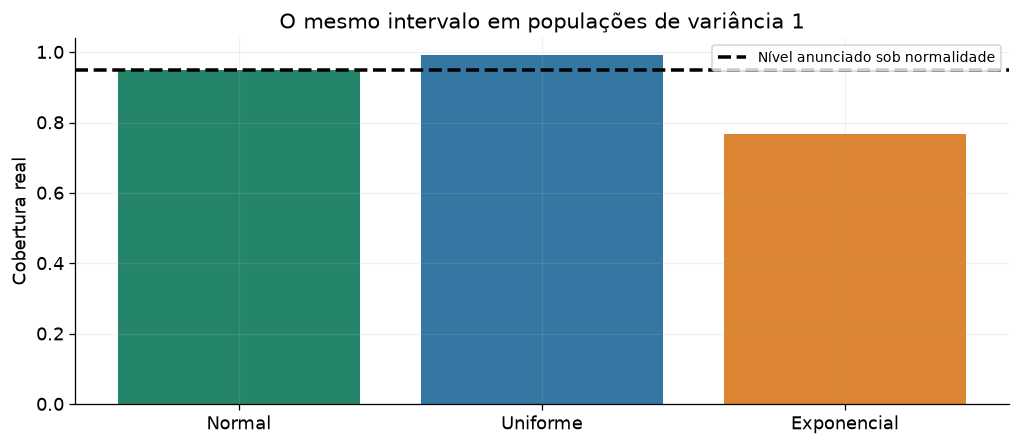

,População,Média de S²,Cobertura do IC χ²
0,Normal,0.99685,0.94967
1,Uniforme,1.00214,0.99208
2,Exponencial,1.00294,0.76700


In [29]:
# Manter S² não enviesado não basta para manter a cobertura do IC χ².
linhas=[]
for nome,dados in modelos.items():
    s2=dados.var(axis=1,ddof=1)
    lo=(n-1)*s2/qh;hi=(n-1)*s2/ql
    linhas.append([nome,s2.mean(),np.mean((lo<=1)&(1<=hi))])
fig,ax=plt.subplots(figsize=(9,4))
ax.bar([l[0] for l in linhas],[l[2] for l in linhas],color=[CORES['verde'],CORES['azul'],CORES['laranja']])
ax.axhline(.95,color='black',ls='--',label='Nível anunciado sob normalidade')
ax.set(ylim=(0,1.04),ylabel='Cobertura real',title='O mesmo intervalo em populações de variância 1');ax.legend(fontsize=9)
figura(fig,'29_IC_variancia_fora_normalidade')
display(pd.DataFrame(linhas,columns=['População','Média de S²','Cobertura do IC χ²']))

### 2.14 Intervalo para a razão das variâncias — Gregory, §6.6.4

Essa construção completa a conexão com a distribuição $F$. Para duas amostras normais independentes, queremos $\rho=\sigma_x^2/\sigma_y^2>0$. Defina $R_S=S_x^2/S_y^2$. O pivô é

$$F=\frac{R_S}{\rho}\sim F_{n_x-1,n_y-1}.$$

Escolhendo os quantis $f_l$ e $f_h$ de caudas iguais e invertendo,

$$f_l\leq\frac{R_S}{\rho}\leq f_h
\iff\boxed{\frac{R_S}{f_h}\leq\rho\leq\frac{R_S}{f_l}}.$$

Observe a mesma troca de extremos do intervalo para $\sigma^2$. O fato de $\rho=1$ estar ou não no intervalo será útil na discussão de testes do próximo capítulo, mas o intervalo já fornece uma faixa de razões compatível com o procedimento de cobertura.

Se invertermos os rótulos das populações, o novo parâmetro é $1/\rho$ e seu intervalo é $[1/H,1/L]$. A fórmula com os graus de liberdade trocados deve dar o mesmo resultado.

Exemplo do livro: IC 95% para σₓ²/σᵧ² = [0.78610, 22.04178]
Razão inversa: [0.04537, 1.27210]


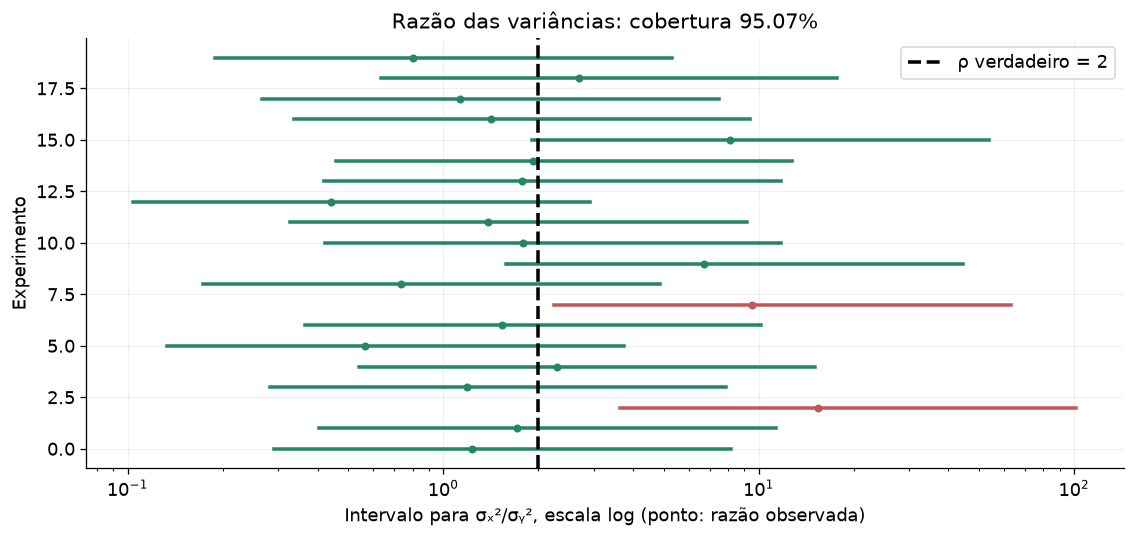

In [31]:
rs=16.65/5.
fl,fh=stats.f.ppf([.025,.975],5,10)
ci_r=np.array([rs/fh,rs/fl])
fl_inv,fh_inv=stats.f.ppf([.025,.975],10,5)
ci_inv=np.array([(1/rs)/fh_inv,(1/rs)/fl_inv])
print(f'Exemplo do livro: IC 95% para σₓ²/σᵧ² = [{ci_r[0]:.5f}, {ci_r[1]:.5f}]')
print(f'Razão inversa: [{ci_inv[0]:.5f}, {ci_inv[1]:.5f}]')
verificar('IC da razão: inverter rótulos preserva o evento',np.allclose(ci_inv,1/ci_r[::-1]))
# Simulação de razões de variâncias, sem impor que a razão populacional seja 1.
rho_pop=2.0
u1=rng.chisquare(5,R);u2=rng.chisquare(10,R)
rs_sim=rho_pop*(u1/5)/(u2/10)
lo_r=rs_sim/fh;hi_r=rs_sim/fl
cobr=(lo_r<=rho_pop)&(rho_pop<=hi_r)
fig,ax=plt.subplots(figsize=(10,4.8))
for j in range(20):
    cor=CORES['verde'] if cobr[j] else CORES['vermelho']
    ax.plot([lo_r[j],hi_r[j]],[j,j],color=cor)
    ax.plot(rs_sim[j],j,'o',color=cor,ms=4)
ax.axvline(rho_pop,color='black',ls='--',label='ρ verdadeiro = 2')
ax.set(xlabel='Intervalo para σₓ²/σᵧ², escala log (ponto: razão observada)',ylabel='Experimento',xscale='log',title=f'Razão das variâncias: cobertura {cobr.mean():.2%}');ax.legend()
figura(fig,'30_IC_razao_variancias')
verificar('Razão de variâncias: cobertura 95%',abs(cobr.mean()-.95)<5*np.sqrt(.95*.05/R))

### 2.15 Exercícios do fim do capítulo — Gregory, §6.8

Vamos usar os quatro valores $D=(0.753,3.795,4.827,2.025)$, assumidos no livro como uma amostra IID normal. Eles não são quatro médias: são **quatro medidas**, das quais extraímos uma média e uma variância.

**1. Variância, desvio padrão e erro padrão.**

$$\bar x=\frac{0.753+3.795+4.827+2.025}{4}=2.850,$$
$$s^2=\frac{(0.753-2.850)^2+(3.795-2.850)^2+(4.827-2.850)^2+(2.025-2.850)^2}{3}.$$

O desvio padrão é $s=\sqrt{s^2}$ e o erro padrão da média $s/2$. Vamos calcular os desvios e seus quadrados em uma tabela, sem omitir a soma.

**2. IC 95% para a média.** Como $\sigma$ é desconhecido, temos $\nu=3$ e usamos $\bar x\pm t_{0.975,3}s/2$. O quantil Student é bem maior que 1.96: só quatro medidas deixam a escala bastante incerta.

**3. Cauda de $\chi^2$ em 30.61 com dez graus de liberdade.** Calculamos $P(\chi_{10}^2>30.61)$; o limiar é o mesmo do exemplo anterior, mas os graus de liberdade são outros. A cauda precisa mudar.

**4. A referência $\sigma_x^2=2\sigma_y^2$.** Os dados são os mesmos $s_x^2/s_y^2=3.33$. Com $\rho_0=2$, o pivô observado é $f=3.33/2=1.665$.

O enunciado impresso passa de $f=1.665$ para uma pergunta sobre “$f\geq3.33$”, misturando os limiares. Vamos explicitar as duas leituras:

$$P_{\rho_0=2}(R_S\geq3.33)=P(F_{5,10}\geq1.665),$$
$$P(F_{5,10}\geq3.33)=P_{\rho_0=2}(R_S\geq6.66).$$

A primeira é a cauda correspondente **à razão observada** sob a referência 2; a segunda responde literalmente ao limiar 3.33 na variável pivotal $F$. Dizer qual variável está no evento evita uma resposta numericamente correta à pergunta errada.

,xᵢ,xᵢ−x̄,(xᵢ−x̄)²
0,0.753,-2.097,4.39741
1,3.795,0.945,0.89302
2,4.827,1.977,3.90853
3,2.025,-0.825,0.68063


Soma dos quadrados = 9.879588
x̄=2.850000; s²=3.293196; s=1.814717; SE=0.907358
Quantil t(3) = 3.182446; IC95% = [-0.037619, 5.737619]
Q3: P(χ²₁₀ > 30.61) = 0.00068034
Q4: P(R_S ≥ 3.33 | ρ=2) = P(F ≥ 1.665) = 0.230216
Q4: P(F ≥ 3.33) = 0.049831


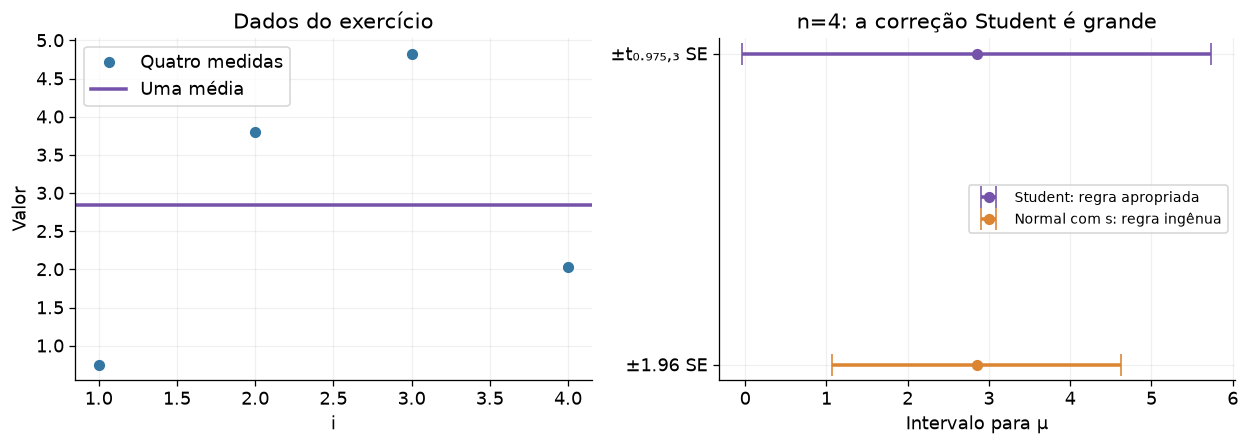

In [32]:
# Resolução aberta dos exercícios: nenhuma função depende de outro notebook.
dados_livro=np.array([.753,3.795,4.827,2.025])
n_livro=len(dados_livro)
xb_livro=dados_livro.mean()
desvios=dados_livro-xb_livro
s2_livro=np.sum(desvios**2)/(n_livro-1)
s_livro=np.sqrt(s2_livro);se_livro=s_livro/np.sqrt(n_livro)
t_livro=stats.t.ppf(.975,n_livro-1)
ci_livro=xb_livro+np.array([-1,1])*t_livro*se_livro
display(pd.DataFrame({'xᵢ':dados_livro,'xᵢ−x̄':desvios,'(xᵢ−x̄)²':desvios**2}))
print(f'Soma dos quadrados = {np.sum(desvios**2):.6f}')
print(f'x̄={xb_livro:.6f}; s²={s2_livro:.6f}; s={s_livro:.6f}; SE={se_livro:.6f}')
print(f'Quantil t(3) = {t_livro:.6f}; IC95% = [{ci_livro[0]:.6f}, {ci_livro[1]:.6f}]')
print(f'Q3: P(χ²₁₀ > 30.61) = {stats.chi2.sf(30.61,10):.8f}')
print(f'Q4: P(R_S ≥ 3.33 | ρ=2) = P(F ≥ 1.665) = {stats.f.sf(1.665,5,10):.6f}')
print(f'Q4: P(F ≥ 3.33) = {stats.f.sf(3.33,5,10):.6f}')
verificar('Exercício 1: média',np.isclose(xb_livro,2.85))
verificar('Exercício 1: variância manual e NumPy',np.isclose(s2_livro,dados_livro.var(ddof=1)))
ci_ind=stats.ttest_1samp(dados_livro,0).confidence_interval(.95)
verificar('Exercício 2: IC manual e SciPy',np.allclose(ci_livro,[ci_ind.low,ci_ind.high]))
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].plot(np.arange(1,5),dados_livro,'o',color=CORES['azul'],label='Quatro medidas')
ax[0].axhline(xb_livro,color=CORES['roxo'],label='Uma média')
ax[0].set(xlabel='i',ylabel='Valor',title='Dados do exercício');ax[0].legend()
ax[1].errorbar(xb_livro,1,xerr=t_livro*se_livro,fmt='o',capsize=7,color=CORES['roxo'],label='Student: regra apropriada')
ax[1].errorbar(xb_livro,0,xerr=zc*se_livro,fmt='o',capsize=7,color=CORES['laranja'],label='Normal com s: regra ingênua')
ax[1].set(xlabel='Intervalo para μ',yticks=[0,1],yticklabels=['±1.96 SE','±t₀.₉₇₅,₃ SE'],title='n=4: a correção Student é grande');ax[1].legend(fontsize=9)
figura(fig,'31_exercicios_gregory')

### 2.16 Uma conexão com a pesquisa: estimar uma amplitude com covariância conhecida

Um modelo simples para um vetor de dados de correlação é

$$\mathbf d=A\mathbf h+\boldsymbol\epsilon,\qquad
\boldsymbol\epsilon\sim\mathcal N_m(\mathbf0,C).$$

Aqui $\mathbf d$ tem $m$ componentes observadas, $\mathbf h\neq0$ é um template conhecido, $A$ é a amplitude desconhecida, e $C$ é a matriz de covariância conhecida, simétrica e positiva definida. Neste exemplo, $\mathbf h$ é adimensional e $A$ tem as unidades dos dados. A normal multivariada tem densidade proporcional a $e^{-\boldsymbol\epsilon^TC^{-1}\boldsymbol\epsilon/2}$.

A soma de quadrados com a métrica da covariância é

$$Q(A)=(\mathbf d-A\mathbf h)^TC^{-1}(\mathbf d-A\mathbf h).$$

Derivando em relação a $A$,

$$\frac{dQ}{dA}=-2\mathbf h^TC^{-1}(\mathbf d-A\mathbf h)=0
\quad\Rightarrow\quad
\hat A=\frac{\mathbf h^TC^{-1}\mathbf d}{\mathbf h^TC^{-1}\mathbf h}.$$

Como $\hat A$ é uma combinação linear dos dados gaussianos,

$$\mathbb E[\hat A]=A,\qquad
\operatorname{Var}(\hat A)=\frac1{\mathbf h^TC^{-1}\mathbf h}.$$

Temos um intervalo normal exato para $A$ sob essas hipóteses. O teorema 3 aparece em outra forma: escreva $C=LL^T$, com $L$ uma matriz triangular invertível. Transformando $\mathbf y=L^{-1}\mathbf d$, $\mathbf g=L^{-1}\mathbf h$, o ruído vira normal com covariância identidade. Ajustar $A$ projeta $\mathbf y$ na direção de $\mathbf g$; restam $m-1$ direções gaussianas independentes. Logo

$$Q(\hat A)\sim\chi_{m-1}^2.$$

Este exemplo mostra por que os graus de liberdade de um ajuste linear surgem de uma **projeção**, como os resíduos da média. Ele também mostra por que não podemos tratar a covariância como diagonal sem verificar.

Uma covariância estimada de um número finito de simulações, seleção do catálogo, dependência entre bins ou dados não gaussianos exigem tratamento adicional. A Student de uma média com $S$ estimado não deve ser transportada automaticamente para uma likelihood com matriz de covariância estimada. O que podemos transportar é o cuidado com a definição da estatística, sua distribuição e o experimento de referência.

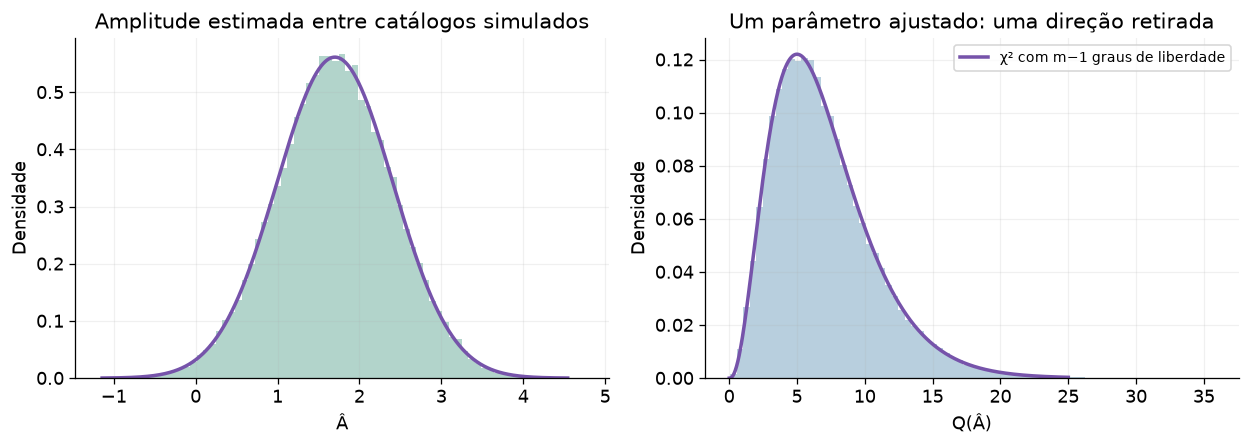

Um catálogo: Â=1.63896; IC95%=[0.24636, 3.03157]
Cobertura entre catálogos: 95.110%; E[Qmin]≈6.99606, esperado=7


In [33]:
# Modelo linear de uma amplitude, com bins correlacionados.
m_bins=8
indices=np.arange(m_bins)
C=.6**np.abs(indices[:,None]-indices[None,:])
h=np.linspace(.3,1.2,m_bins)
A_real=1.7
L=linalg.cholesky(C,lower=True)
dados_amp=A_real*h+rng.normal(size=(R,m_bins))@L.T
Cinv_h=linalg.solve(C,h,assume_a='pos')
info=h@Cinv_h
Ahat=dados_amp@Cinv_h/info
se_A=1/np.sqrt(info)
resid=dados_amp-Ahat[:,None]*h
# Resolver o sistema evita formar a inversa de C explicitamente.
resid_branco=linalg.solve_triangular(L,resid.T,lower=True).T
Qmin=np.sum(resid_branco**2,axis=1)
fig,ax=plt.subplots(1,2,figsize=(11,4))
gx=np.linspace(A_real-4*se_A,A_real+4*se_A,800)
ax[0].hist(Ahat,bins=75,density=True,alpha=.35,color=CORES['verde'])
ax[0].plot(gx,stats.norm.pdf(gx,A_real,se_A),color=CORES['roxo'])
ax[0].set(xlabel='Â',ylabel='Densidade',title='Amplitude estimada entre catálogos simulados')
gq=np.linspace(.01,25,800)
ax[1].hist(Qmin,bins=75,density=True,alpha=.35,color=CORES['azul'])
ax[1].plot(gq,stats.chi2.pdf(gq,m_bins-1),color=CORES['roxo'],label='χ² com m−1 graus de liberdade')
ax[1].set(xlabel='Q(Â)',ylabel='Densidade',title='Um parâmetro ajustado: uma direção retirada');ax[1].legend(fontsize=9)
figura(fig,'32_amplitude_covariancia')
cobA=np.mean(np.abs(Ahat-A_real)<=zc*se_A)
print(f'Um catálogo: Â={Ahat[0]:.5f}; IC95%=[{Ahat[0]-zc*se_A:.5f}, {Ahat[0]+zc*se_A:.5f}]')
print(f'Cobertura entre catálogos: {cobA:.3%}; E[Qmin]≈{Qmin.mean():.5f}, esperado={m_bins-1}')
verificar('Amplitude: variância prevista pela covariância',abs(Ahat.var()/se_A**2-1)<.03)
verificar('Amplitude: cobertura 95%',abs(cobA-.95)<5*np.sqrt(.95*.05/R))
verificar('Amplitude: χ² residual médio',abs(Qmin.mean()-(m_bins-1))<.12)

### 2.17 Conta complementar: a variância de $S^2$ fora da população normal

Para não deixar sem dedução a fórmula da seção 1.10, tome $Y_i=X_i-\mu$, com $\mathbb E[Y_i]=0$, $\mathbb E[Y_i^2]=\sigma^2$ e $\mathbb E[Y_i^4]=\mu_4<\infty$. Defina $A_2=\sum_iY_i^2$ e $B_1=\sum_iY_i$. Então $(n-1)S^2=A_2-B_1^2/n$.

Pela independência e porque produtos com um fator isolado de média zero desaparecem,

$$\mathbb E[A_2^2]=n\mu_4+n(n-1)\sigma^4,$$
$$\mathbb E[A_2B_1^2]=\mathbb E[A_2^2],$$
$$\mathbb E[B_1^4]=n\mu_4+3n(n-1)\sigma^4.$$

Na última conta, o coeficiente 3 vem de $6\binom n2$ pares de quadrados em uma expansão de quarta potência. Assim,

$$\mathbb E[(A_2-B_1^2/n)^2]
=\left(1-\frac2n\right)\mathbb E[A_2^2]+\frac1{n^2}\mathbb E[B_1^4]
=\frac{(n-1)^2}{n}\mu_4+\frac{(n-1)(n^2-2n+3)}{n}\sigma^4.$$

Dividindo por $(n-1)^2$ e subtraindo $\mathbb E[S^2]^2=\sigma^4$, recuperamos

$$\operatorname{Var}(S^2)=\frac1n\left[\mu_4-\frac{n-3}{n-1}\sigma^4\right].$$

A normal, a uniforme padronizada e a exponencial de média 1 têm $\mu_4=3$, $9/5$ e 9, respectivamente, quando $\sigma^2=1$. Isso explica as diferenças de dispersão vistas na simulação, sem confundir não enviesamento com uma forma universal de PDF.

In [34]:
# Conferir os momentos de quarta ordem por integração e a dispersão de S².
dists4={'Normal':stats.norm(),
        'Uniforme':stats.uniform(-np.sqrt(3),2*np.sqrt(3)),
        'Exponencial':stats.expon()}
linhas=[]
for nome,dist in dists4.items():
    m4=dist.expect(lambda x:(x-dist.mean())**4)
    var_teor=(m4-(n-3)/(n-1))/n
    var_sim=modelos[nome].var(axis=1,ddof=1).var()
    linhas.append([nome,m4,var_teor,var_sim])
    verificar(f'Var(S²) fora normalidade: {nome}',abs(var_sim/var_teor-1)<.08)
display(pd.DataFrame(linhas,columns=['População','μ₄','Var(S²) analítica','Var(S²) simulada']))

,População,μ₄,Var(S²) analítica,Var(S²) simulada
0,Normal,3.0,0.22222,0.22076
1,Uniforme,1.8,0.10222,0.10304
2,Exponencial,9.0,0.82222,0.81748


### 2.18 Escolher a fórmula a partir do experimento

| O que queremos estimar | Hipóteses | Intervalo central de nível $1-\alpha$ |
|:--|:--|:--|
| $\mu$, $\sigma$ conhecido | Amostra IID normal | $\bar x\pm z_{1-\alpha/2}\sigma/\sqrt n$ |
| $\mu$, $\sigma$ desconhecido | Amostra IID normal, $n\geq2$ | $\bar x\pm t_{1-\alpha/2,n-1}s/\sqrt n$ |
| $\Delta$, variâncias conhecidas | Duas amostras normais independentes | $\bar x-\bar y\pm z_{1-\alpha/2}\sqrt{\sigma_x^2/n_x+\sigma_y^2/n_y}$ |
| $\Delta$, variância comum desconhecida | Duas amostras normais independentes | Pooled, com $\nu=n_x+n_y-2$ |
| $\Delta$, variâncias distintas desconhecidas | Duas amostras normais independentes | Welch, **aproximado**, com $\hat\nu$ por ajuste de momentos |
| $\sigma^2$ | Amostra IID normal, média desconhecida | $[(n-1)s^2/q_{1-\alpha/2},(n-1)s^2/q_{\alpha/2}]$ |
| $\rho=\sigma_x^2/\sigma_y^2$ | Duas amostras normais independentes | $[(s_x^2/s_y^2)/f_{1-\alpha/2},(s_x^2/s_y^2)/f_{\alpha/2}]$ |

Os quantis de $\chi^2$ e $F$ na tabela têm os graus de liberdade derivados nas seções anteriores. Esses intervalos são exatos sob as hipóteses indicadas, salvo o Welch e as aproximações explicitadas. Se usamos o TLC para uma população não normal, precisamos avaliar a qualidade da aproximação; não basta afirmar que “$n$ é grande”.

Antes de calcular, podemos fazer quatro perguntas: **qual é a amostra? qual é o parâmetro? o que é conhecido? qual distribuição justifica o pivô?** Isso resolve grande parte das ambiguidades de notação.

### 2.19 O que deve ficar claro ao encerrar o capítulo

Uma amostra de $n$ medidas fornece uma média observada e uma variância observada. Muitas amostras fornecem muitos valores dessas estatísticas. As distribuições amostrais descrevem essas possíveis repetições; a simulação permite enxergá-las, mas as fórmulas se aplicam também quando só temos um experimento real.

Os resultados de não enviesamento descrevem médias sobre amostras, os intervalos de confiança descrevem cobertura de uma regra e as posteriores descrevem incerteza sobre parâmetros condicionada aos dados e à prior. São perguntas relacionadas, com condicionamentos diferentes.

Na próxima etapa, o capítulo 7 usará as distribuições deste notebook como referências para avaliar estatísticas sob hipóteses especificadas. As caudas que calculamos já preparam esse assunto, mantendo a distinção entre probabilidade de dados sob uma hipótese e probabilidade da hipótese dados os resultados.

**Perguntas para testar o entendimento, antes de olhar a resposta abaixo.** Por que $n$ medidas não geram $n$ médias? Por que $S^2$ ser não enviesado não garante um IC qui-quadrado correto? Por que a normal muda para a Student quando estimamos a escala? Por que o quantil maior aparece no denominador do limite inferior de um IC de variância?

**Respostas.** Uma média usa o conjunto inteiro; para várias médias independentes precisamos de novos conjuntos. O não enviesamento usa hipóteses mais fracas que a distribuição qui-quadrado. A Student é a distribuição de uma razão com escala aleatória, cuja independência foi provada sob normalidade. E inverter uma desigualdade entre quantidades positivas troca a ordem dos extremos.